# 🇮🇳 Vayu AQI Intelligence
### A Production-Grade Machine Learning & Forecasting Platform

**Author:** Anandhu Suresh  
**Project Type:** End-to-End Data Engineering & Machine Learning Portfolio

---

### Executive Summary

Most machine learning projects attempting to predict Air Quality Index (AQI) fall into the **"99% Accuracy Trap"**—they achieve suspiciously high R² scores because the model is simply reverse-engineering the deterministic mathematical formula used by the Central Pollution Control Board (CPCB). 

This project diagnoses that data leakage, establishes a rigorous **Persistence Baseline** for forecasting, and utilizes unsupervised **station clustering** to deploy specialist models that successfully outperform the baseline on the most critical metric: **Severe Air Quality F1-score**.

> **Why this matters:** A generic city-wide AQI alert is a blunt instrument. By proving that different monitoring stations require different ML models, this platform provides the analytical foundation for highly targeted, life-saving public health interventions.

---

###  Project at a Glance
*   **Historical Data:** 17 Years (2010–2026) of CPCB Monitoring Data
*   **Live Pipeline:** Real-time API Ingestion & Automated Excel Reporting
*   **Total Observations:** 110,838 Hourly Records | 5,290 Daily Aggregations
*   **Models Evaluated:** 9 Regression, 7 Classification, 1 Clustering Algorithm
*   **Ultimate Win:** Specialist models beat global models and the persistence baseline on Severe AQI prediction (F1 = 0.429 vs 0.407).

---

###  Table of Contents

**Phase 1: Data Engineering & Discovery**
*   [01. Project Introduction & Business Context](#01-project-introduction--business-context)
*   [02. Data Sources & Collection](#02-data-sources--collection)
*   [03. Dataset Understanding](#03-dataset-understanding)
*   [04. Data Quality & Preparation](#04-data-quality--preparation)
*   [05. Exploratory Data Analysis (8 Discoveries)](#05-exploratory-data-analysis)
*   [06. KPI & Air Quality Analysis](#06-kpi--air-quality-analysis)

**Phase 2: The Machine Learning Trap**
*   [07. Regression Investigation — The ML Trap](#07-regression-investigation--the-ml-trap)
*   [08. Classification — AQI Forecasting](#08-classification--aqi-forecasting)
*   [09. Persistence Baseline & Model Comparison](#09-persistence-baseline--model-comparison)

**Phase 3: Advanced Forecasting & Segmentation**
*   [10. Unsupervised Learning — Station Clustering](#10-unsupervised-learning--station-clustering)
*   [11. Specialist Model Evaluation](#11-specialist-model-evaluation)
*   [12. Cross-Model Comparison](#12-cross-model-comparison)

**Phase 4: Business Impact & Future Scope**
*   [13. Major Business & Environmental Insights](#13-major-business--environmental-insights)
*   [14. Recommendations](#14-recommendations)
*   [15. Limitations & Future Scope](#15-limitations--future-scope)
*   [16. Final Conclusion](#16-final-conclusion)

In [1]:
# =============================================================================
# Cell 1 — Environment Setup & High-End Visual Styling
# =============================================================================

import sys
from pathlib import Path
import warnings

# Setup paths
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Premium styling for a portfolio presentation
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 200,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": True,
    "legend.framealpha": 0.9,
})

ASSETS = PROJECT_ROOT / "assets"
ASSETS.mkdir(parents=True, exist_ok=True)
RNG = 42

print(f" Environment configured. Project root: {PROJECT_ROOT.name}")
print(f" Pandas {pd.__version__} | NumPy {np.__version__} | Matplotlib {plt.matplotlib.__version__}")

 Environment configured. Project root: vayu-aqi-intelligence
 Pandas 1.5.3 | NumPy 1.23.5 | Matplotlib 3.7.0


## 01. Project Introduction & Business Context

### The Real-World Problem: The Need for Early Warnings
India, and specifically the Delhi-NCR region, faces a recurring public health crisis due to toxic air quality. When the Air Quality Index (AQI) crosses 300 into the "Very Poor" or "Severe" categories, schools close and emergency respiratory hospitalizations spike. 

Public health officials do not just need to know what the AQI is *today*—they need to know what it will be **tomorrow** so they can issue early warnings, restrict construction, or advise citizens to stay indoors. 

### The Analytical Trap: The "99% Accuracy" Illusion
To predict tomorrow's air quality, most data scientists build a Machine Learning model using today's pollutant data (PM2.5, PM10, NO2, etc.). They often achieve an unbelievable accuracy (R² > 0.99) and assume they have built a successful forecasting tool.

**This is a trap.** In India, the official AQI is not an independent measurement; it is mathematically calculated using a fixed formula based on those exact same pollutants. If a model uses today's pollutants to predict today's AQI, it isn't forecasting the future. It is simply reverse-engineering a known mathematical formula. It has learned nothing about weather patterns, seasonal shifts, or tomorrow's air.

### The Vayu AQI Intelligence Solution
To build a system that actually provides value to public health officials, we designed a **Dual-Pipeline Architecture** that separates *monitoring* from *forecasting*:

1.  **Live ETL Pipeline (Real-Time Monitoring):** A robust Data Engineering pipeline that connects to the government API. It fetches the current data, handles missing values, calculates the official CPCB math, and generates automated Excel reports for stakeholders.
2.  **Historical ML Pipeline (True Forecasting):** A Machine Learning pipeline that analyzes 17 years of data to predict **tomorrow's** AQI. It explicitly diagnoses and prevents the mathematical leakage trap, establishes a realistic "Persistence Baseline", and uses unsupervised clustering to train localized, specialist models that improve the accuracy of severe smog day predictions.

Let's visualize how these two pipelines operate side-by-side within the repository.

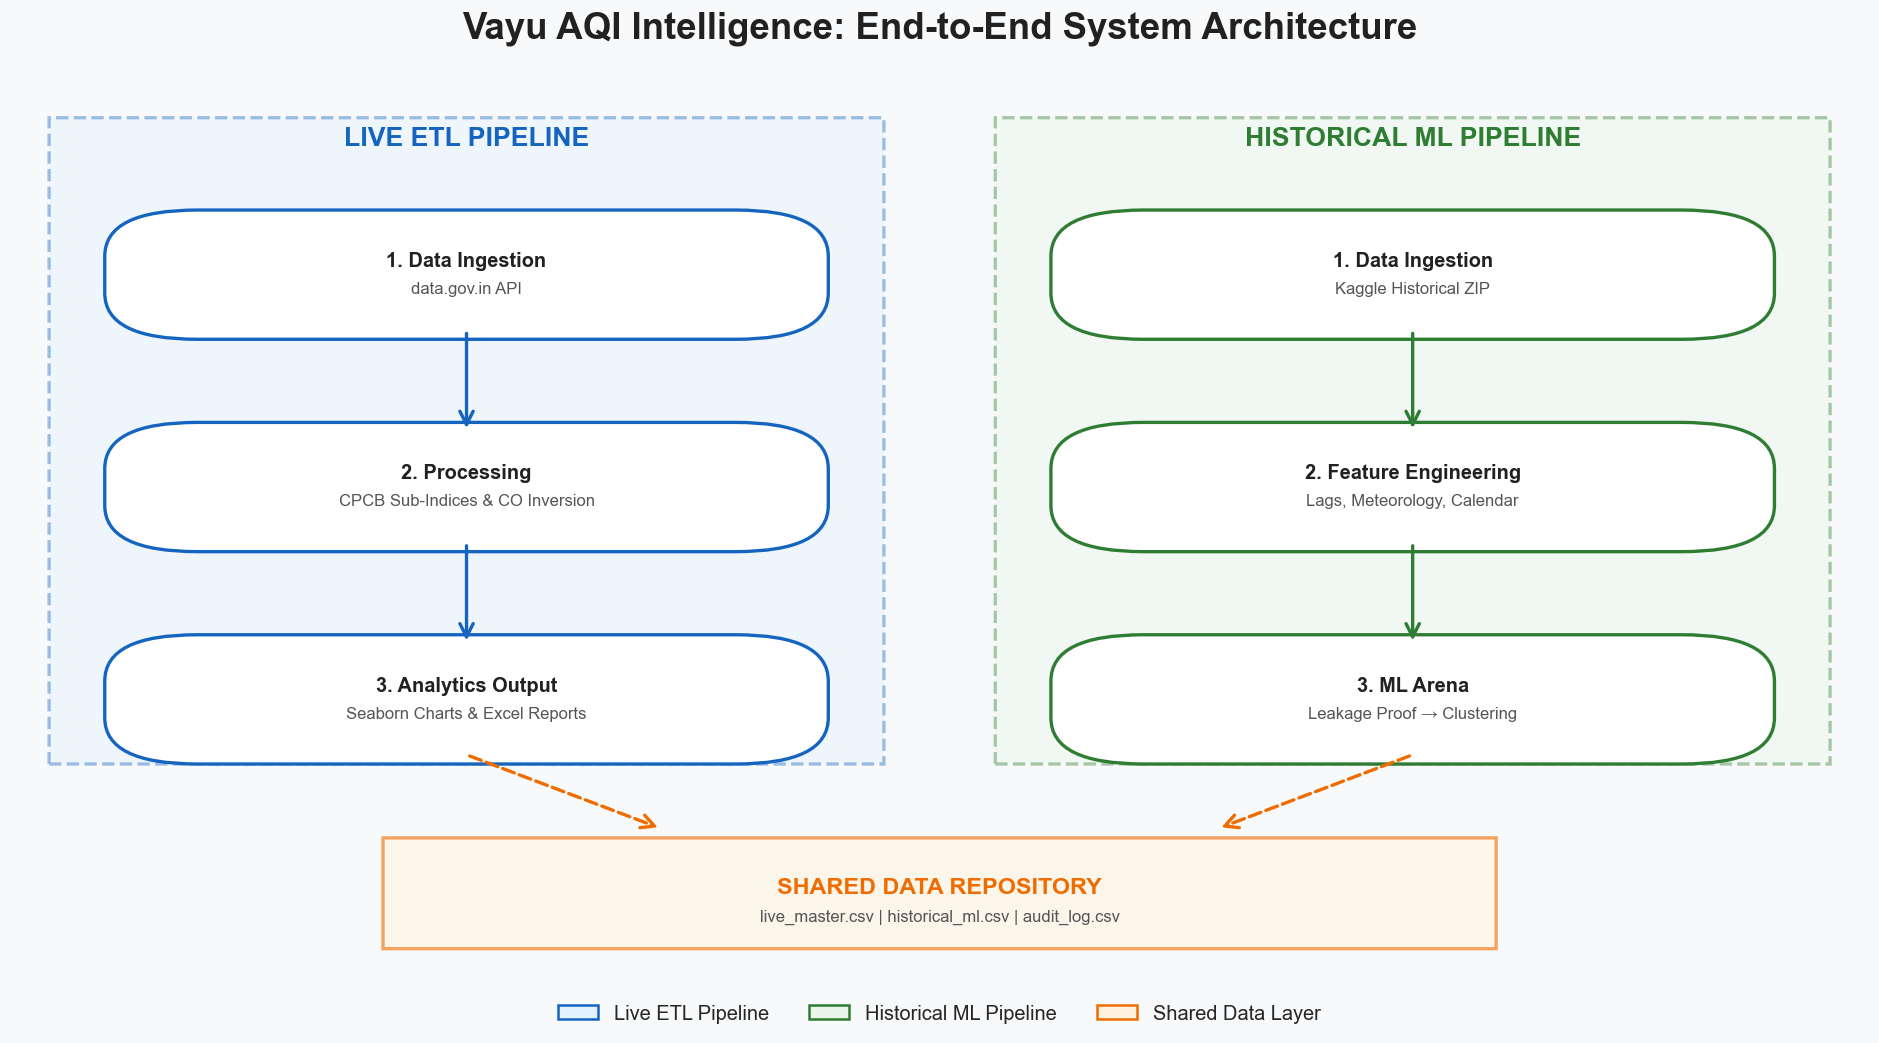

In [2]:
# =============================================================================
# Cell 3 — Visualizing the Dual-Pipeline Architecture (Fixed & Professional)
# =============================================================================

import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(16, 9), facecolor='#f8f9fa')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis('off') # Hide the axes

# --- Color Palette ---
c_bg_live = "#e3f2fd"   # Light Blue background
c_border_live = "#1565c0" # Dark Blue border
c_bg_ml = "#e8f5e9"     # Light Green background
c_border_ml = "#2e7d32"   # Dark Green border
c_bg_data = "#fff3e0"   # Light Orange background
c_border_data = "#ef6c00" # Dark Orange border
c_node_live = "#ffffff"
c_node_ml = "#ffffff"
c_node_data = "#ffffff"
text_col = "#212121"

# --- Helper Function for Nodes ---
def draw_node(x, y, width, height, title, subtitle, bg_color, border_color):
    # Correctly placing the box from the bottom-left corner
    box = FancyBboxPatch((x - width/2, y - height/2), width, height,
                         boxstyle="round,pad=0.02,rounding_size=0.05",
                         ec=border_color, fc=bg_color, lw=2, zorder=3)
    ax.add_patch(box)
    # Title
    ax.text(x, y + 0.015, title, ha='center', va='center', fontsize=12, 
            fontweight='bold', color=text_col, zorder=4)
    # Subtitle
    ax.text(x, y - 0.015, subtitle, ha='center', va='center', fontsize=10, 
            color="#555555", zorder=4)

# =============================================================================
# 1. BACKGROUND ZONES (The Pipelines)
# =============================================================================
# Live Pipeline Zone
ax.add_patch(FancyBboxPatch((0.02, 0.25), 0.45, 0.70, boxstyle="round,pad=0.0", 
                            ec=c_border_live, fc=c_bg_live, alpha=0.4, lw=2, ls='--'))
ax.text(0.245, 0.92, "LIVE ETL PIPELINE", ha='center', fontsize=16, 
        fontweight='bold', color=c_border_live)

# ML Pipeline Zone
ax.add_patch(FancyBboxPatch((0.53, 0.25), 0.45, 0.70, boxstyle="round,pad=0.0", 
                            ec=c_border_ml, fc=c_bg_ml, alpha=0.4, lw=2, ls='--'))
ax.text(0.755, 0.92, "HISTORICAL ML PIPELINE", ha='center', fontsize=16, 
        fontweight='bold', color=c_border_ml)

# Data Storage Zone
ax.add_patch(FancyBboxPatch((0.20, 0.05), 0.60, 0.12, boxstyle="round,pad=0.0", 
                            ec=c_border_data, fc=c_bg_data, alpha=0.6, lw=2))
ax.text(0.50, 0.11, "SHARED DATA REPOSITORY", ha='center', fontsize=14, 
        fontweight='bold', color=c_border_data)

# =============================================================================
# 2. NODES (The Steps)
# =============================================================================
# Live Nodes
draw_node(0.245, 0.78, 0.35, 0.10, "1. Data Ingestion", "data.gov.in API", c_node_live, c_border_live)
draw_node(0.245, 0.55, 0.35, 0.10, "2. Processing", "CPCB Sub-Indices & CO Inversion", c_node_live, c_border_live)
draw_node(0.245, 0.32, 0.35, 0.10, "3. Analytics Output", "Seaborn Charts & Excel Reports", c_node_live, c_border_live)

# ML Nodes
draw_node(0.755, 0.78, 0.35, 0.10, "1. Data Ingestion", "Kaggle Historical ZIP", c_node_ml, c_border_ml)
draw_node(0.755, 0.55, 0.35, 0.10, "2. Feature Engineering", "Lags, Meteorology, Calendar", c_node_ml, c_border_ml)
draw_node(0.755, 0.32, 0.35, 0.10, "3. ML Arena", "Leakage Proof → Clustering", c_node_ml, c_border_ml)

# Data Node Text
ax.text(0.50, 0.08, "live_master.csv | historical_ml.csv | audit_log.csv", 
        ha='center', fontsize=10, color="#555555")

# =============================================================================
# 3. ARROWS
# =============================================================================
# Downward arrows (Live)
ax.annotate("", xy=(0.245, 0.61), xytext=(0.245, 0.72), arrowprops=dict(arrowstyle="->", color=c_border_live, lw=2, mutation_scale=20), zorder=5)
ax.annotate("", xy=(0.245, 0.38), xytext=(0.245, 0.49), arrowprops=dict(arrowstyle="->", color=c_border_live, lw=2, mutation_scale=20), zorder=5)

# Downward arrows (ML)
ax.annotate("", xy=(0.755, 0.61), xytext=(0.755, 0.72), arrowprops=dict(arrowstyle="->", color=c_border_ml, lw=2, mutation_scale=20), zorder=5)
ax.annotate("", xy=(0.755, 0.38), xytext=(0.755, 0.49), arrowprops=dict(arrowstyle="->", color=c_border_ml, lw=2, mutation_scale=20), zorder=5)

# Arrows pointing from Outputs to Shared Data Repository
ax.annotate("", xy=(0.35, 0.18), xytext=(0.245, 0.26), arrowprops=dict(arrowstyle="->", color=c_border_data, lw=2, ls='--', mutation_scale=20), zorder=5)
ax.annotate("", xy=(0.65, 0.18), xytext=(0.755, 0.26), arrowprops=dict(arrowstyle="->", color=c_border_data, lw=2, ls='--', mutation_scale=20), zorder=5)

# =============================================================================
# 4. TITLE & LEGEND
# =============================================================================
plt.title("Vayu AQI Intelligence: End-to-End System Architecture", 
          fontsize=22, fontweight='bold', pad=20, color=text_col)

legend_elements = [
    mpatches.Patch(facecolor=c_bg_live, edgecolor=c_border_live, label='Live ETL Pipeline'),
    mpatches.Patch(facecolor=c_bg_ml, edgecolor=c_border_ml, label='Historical ML Pipeline'),
    mpatches.Patch(facecolor=c_bg_data, edgecolor=c_border_data, label='Shared Data Layer')
]
ax.legend(handles=legend_elements, loc='lower center', bbox_to_anchor=(0.5, -0.05), 
          ncol=3, frameon=False, fontsize=12)

plt.tight_layout()
plt.show()

## 02. Data Sources & Collection

A robust analytics platform relies on credible data. The Vayu AQI Intelligence project uses two distinct data sources, reflecting the dual-pipeline architecture:

1.  **Live API (The Monitor):** We query the `data.gov.in` API. This provides a real-time snapshot of hourly AQI readings. However, APIs are notoriously fragile. Our ingestion script includes retry logic, pagination handling, and a browser User-Agent header to bypass Web Application Firewalls (WAF). 
2.  **Historical Kaggle Dataset (The Forecaster):** We utilize a massive 17-year historical dataset (2010–2026) from 95 monitoring stations. This dataset arrived as a nested ZIP file containing thousands of individual CSVs.

### The Engineering Challenge: Long vs. Wide Formats
As shown in the code output below, the **Live API returns a "Long" format** (one row per pollutant per station). To train Machine Learning models, we must pivot this into a **"Wide" format** (one row per station, with columns for PM2.5, PM10, NO2, etc.). 

### Data Quality Reality Check
When we load the raw historical dataset, we encounter the realities of real-world environmental data:
*   **Messy Names:** Station names contain raw file paths (e.g., `2010\site_115_NSIT_Dwarka...`).
*   **Sensor Evolution:** In 2010, many stations only recorded NO2. PM2.5 and PM10 sensors were added years later, resulting in high missingness.
*   **Granularity:** We ingest **146,708 hourly rows**, but our forecasting models later aggregate this down to **5,290 daily rows** (because predicting tomorrow's AQI bucket is a daily decision).

Let's look at the raw data proof and the transformation.

In [3]:
# =============================================================================
# Cell 5 — Data Ingestion Proof: Live API vs Historical Data
# =============================================================================

import json
import pandas as pd
from pathlib import Path
from IPython.display import display, HTML

# Setup paths to read the actual project data
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
HISTORICAL_PATH = PROJECT_ROOT / "data" / "processed" / "historical_ml.csv"

# -----------------------------------------------------------------------------
# 1. Live API Payload Example (The "Long" Format)
# -----------------------------------------------------------------------------
# The API returns one row per pollutant, per station, per hour.
live_api_long = [
    {"station": "Anand Vihar", "last_update": "18-11-2026 14:00:00", "pollutant_id": "PM2.5", "avg_value": "178"},
    {"station": "Anand Vihar", "last_update": "18-11-2026 14:00:00", "pollutant_id": "PM10", "avg_value": "245"},
    {"station": "Anand Vihar", "last_update": "18-11-2026 14:00:00", "pollutant_id": "NO2", "avg_value": "85"}
]

print("=" * 80)
print("📡 LIVE API SNAPSHOT (data.gov.in) — Raw 'Long' Format")
print("=" * 80)
display(pd.DataFrame(live_api_long).style.hide(axis="index").set_properties(**{'text-align': 'left'}))

# -----------------------------------------------------------------------------
# 2. The Transformation (Long -> Wide)
# -----------------------------------------------------------------------------
# Our cleaner_live.py uses pivot_table to transform this into the ML-ready format.
df_long = pd.DataFrame(live_api_long)
df_wide = df_long.pivot_table(
    index=["station", "last_update"], 
    columns="pollutant_id", 
    values="avg_value", 
    aggfunc="first"
).reset_index()
df_wide.columns.name = None

print("\n" + "=" * 80)
print(" TRANSFORMATION — Pivoted 'Wide' Format (Ready for ML)")
print("=" * 80)
display(df_wide.style.hide(axis="index").set_properties(**{'text-align': 'left'}))

# -----------------------------------------------------------------------------
# 3. Historical Dataset (Loading actual data from disk)
# -----------------------------------------------------------------------------
print("\n" + "=" * 80)
print(" HISTORICAL KAGGLE DATASET — Loaded from local repository")
print("=" * 80)

if HISTORICAL_PATH.exists():
    # Load the actual dataset we built
    hist_df = pd.read_csv(HISTORICAL_PATH)
    print(f" Successfully loaded historical_ml.csv")
    print(f"   - Total Rows: {len(hist_df):,}")
    print(f"   - Total Columns: {hist_df.shape[1]}")
    print(f"   - Unique Stations: {hist_df['station'].nunique()}")
    print(f"   - Date Range: {hist_df['timestamp_utc'].min()} to {hist_df['timestamp_utc'].max()}")
    print("\nSample of the actual processed data:")
    display(hist_df[["station", "timestamp_utc", "PM2.5", "PM10", "NO2", "AT", "AQI"]].head(3).style.hide(axis="index"))
else:
    print(f" Dataset not found at {HISTORICAL_PATH}. Make sure you ran the cleaner scripts.")

📡 LIVE API SNAPSHOT (data.gov.in) — Raw 'Long' Format


station,last_update,pollutant_id,avg_value
Anand Vihar,18-11-2026 14:00:00,PM2.5,178
Anand Vihar,18-11-2026 14:00:00,PM10,245
Anand Vihar,18-11-2026 14:00:00,NO2,85



 TRANSFORMATION — Pivoted 'Wide' Format (Ready for ML)


station,last_update,NO2,PM10,PM2.5
Anand Vihar,18-11-2026 14:00:00,85,245,178



 HISTORICAL KAGGLE DATASET — Loaded from local repository
 Successfully loaded historical_ml.csv
   - Total Rows: 146,708
   - Total Columns: 26
   - Unique Stations: 95
   - Date Range: 2009-12-31T18:30:00Z to 2026-09-30T17:30:00Z

Sample of the actual processed data:


station,timestamp_utc,PM2.5,PM10,NO2,AT,AQI
2010\site_115_NSIT_Dwarka_Delhi_CPCB_1Hr,2010-01-13T12:30:00Z,nan,nan,13.230000,nan,nan
2010\site_115_NSIT_Dwarka_Delhi_CPCB_1Hr,2010-01-13T13:30:00Z,nan,nan,12.510000,nan,nan
2010\site_115_NSIT_Dwarka_Delhi_CPCB_1Hr,2010-01-13T14:30:00Z,nan,nan,11.140000,nan,nan


## 03. Dataset Understanding

Before building any models, we must understand the statistical behavior of our historical data. We have a **panel dataset** consisting of **146,708 hourly observations** across **95 monitoring stations** spanning 17 years. 

### The Core Variables
The dataset contains 26 columns, which can be grouped into:
*   **Target:** `AQI` (Air Quality Index)
*   **Pollutants:** PM2.5, PM10, NO2, SO2, CO, OZONE, NH3
*   **Meteorology:** Ambient Temperature (AT), Relative Humidity (RH), Wind Speed (WS), Rain
*   **Engineered Features:** Day of week, Season, Diwali offset, Lockdown flags

### The "Right-Skew" Reality
If we plot the distribution of AQI and PM2.5, we will see a classic **right-skewed (log-normal) distribution**. Most days are in the moderate range, but there is a long "tail" of extreme, toxic days (like Diwali or winter inversions). 

**Why this matters for Machine Learning:** Because of this extreme skew, using the *mean* to fill missing values would drag the average upward and distort the model. This statistical distribution visually justifies our architectural decision to use **`SimpleImputer(strategy="median")`** inside our ML pipelines. The median is robust to these extreme toxic spikes.

Let's visualize the distributions and correlations of our primary pollutants.

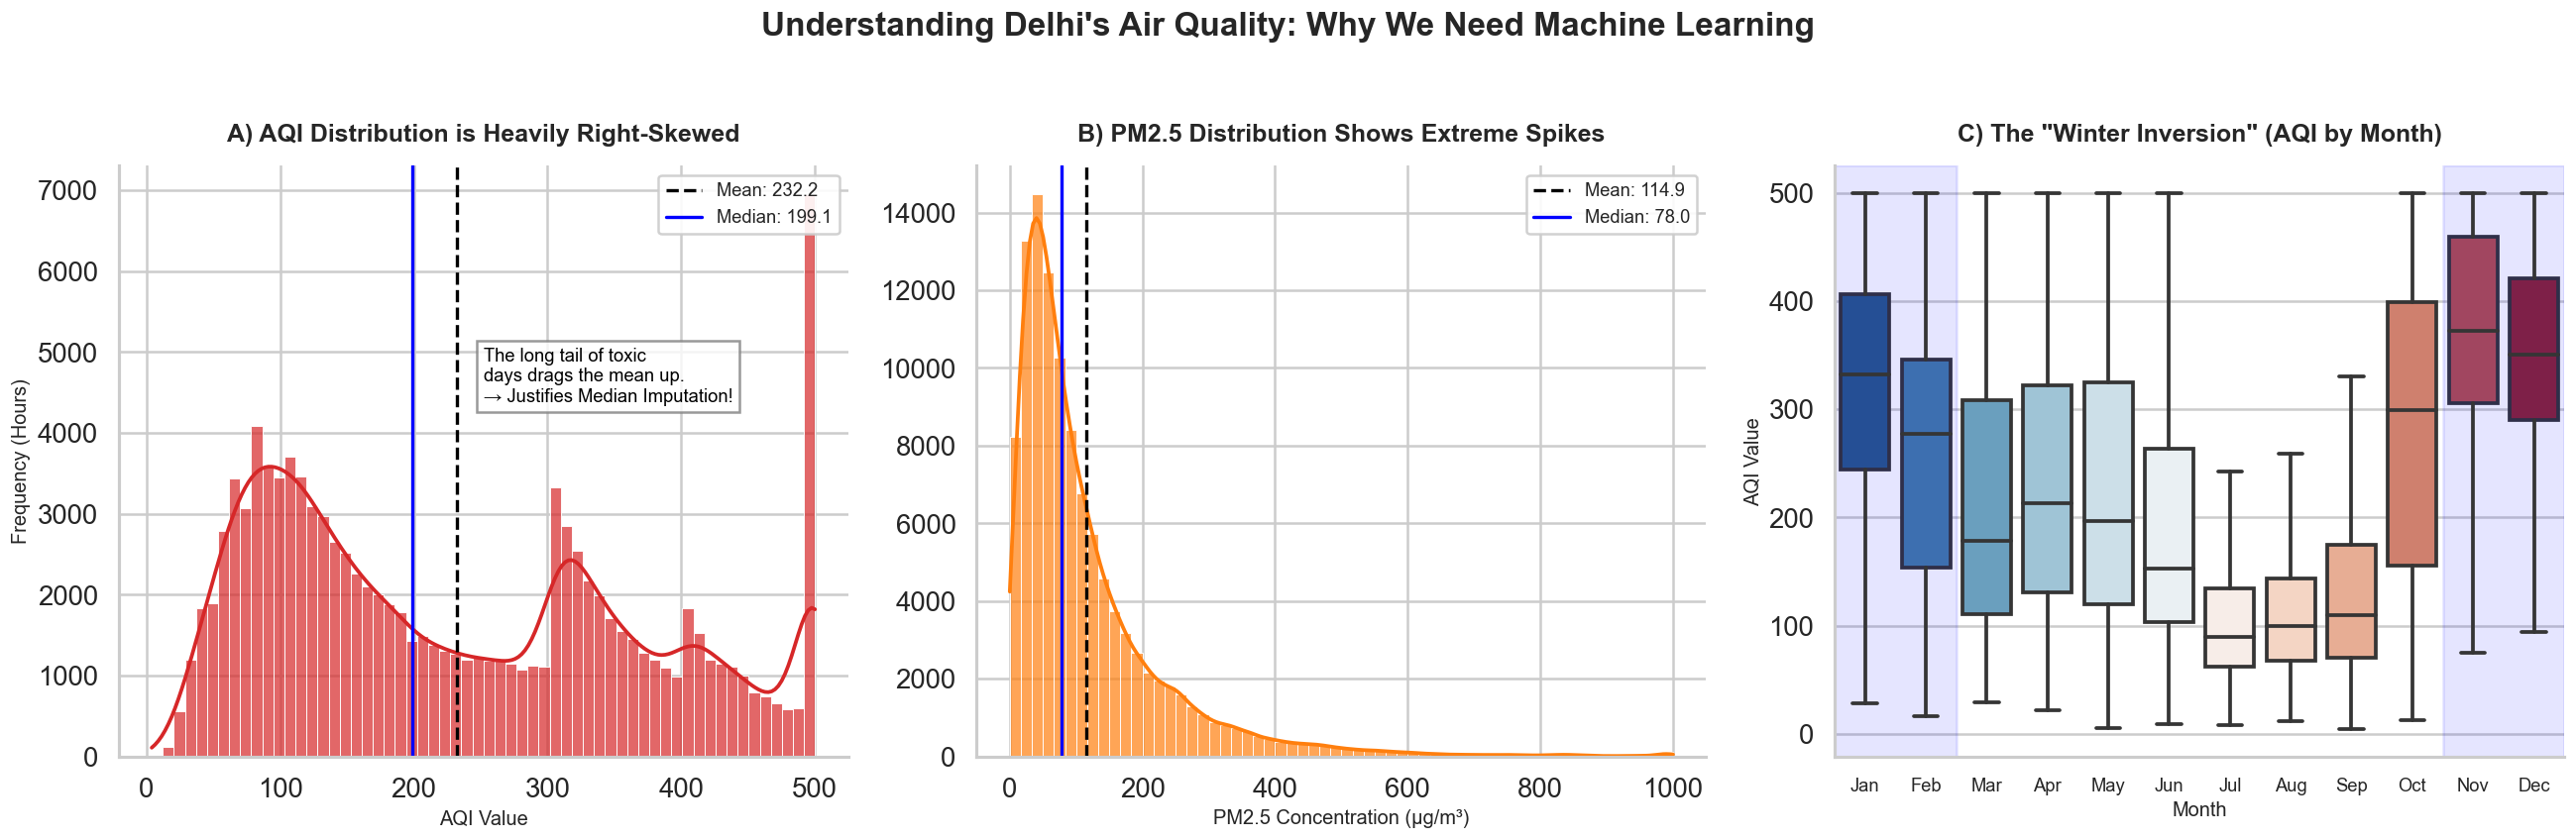

In [4]:
# =============================================================================
# Cell 7 — Statistical Distributions & Temporal Reality
# =============================================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from pathlib import Path

# Load data
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "historical_ml.csv")

# Extract month for temporal analysis
df['timestamp_utc'] = pd.to_datetime(df['timestamp_utc'], errors='coerce', utc=True)
df['Month'] = df['timestamp_utc'].dt.month
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# Set up a stunning 1x3 grid
fig, axes = plt.subplots(1, 3, figsize=(22, 7))

# -----------------------------------------------------------------------------
# Panel 1: AQI Distribution (Proving the Right-Skew)
# -----------------------------------------------------------------------------
sns.histplot(df['AQI'].dropna(), bins=60, kde=True, color='#d62728', alpha=0.7, ax=axes[0])
axes[0].set_title('A) AQI Distribution is Heavily Right-Skewed', fontsize=15, fontweight='bold', pad=15)
axes[0].set_xlabel('AQI Value', fontsize=12)
axes[0].set_ylabel('Frequency (Hours)', fontsize=12)

# Add mean/median lines to justify median imputation
mean_aqi = df['AQI'].mean()
median_aqi = df['AQI'].median()
axes[0].axvline(mean_aqi, color='black', linestyle='--', lw=2, label=f"Mean: {mean_aqi:.1f}")
axes[0].axvline(median_aqi, color='blue', linestyle='-', lw=2, label=f"Median: {median_aqi:.1f}")
axes[0].legend(fontsize=11, loc='upper right')
axes[0].text(mean_aqi + 20, axes[0].get_ylim()[1]*0.6, 
             "The long tail of toxic\ndays drags the mean up.\n→ Justifies Median Imputation!", 
             fontsize=11, color='black', bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray'))

# -----------------------------------------------------------------------------
# Panel 2: PM2.5 Distribution
# -----------------------------------------------------------------------------
sns.histplot(df['PM2.5'].dropna(), bins=60, kde=True, color='#ff7f0e', alpha=0.7, ax=axes[1])
axes[1].set_title('B) PM2.5 Distribution Shows Extreme Spikes', fontsize=15, fontweight='bold', pad=15)
axes[1].set_xlabel('PM2.5 Concentration (µg/m³)', fontsize=12)
axes[1].set_ylabel('')

mean_pm = df['PM2.5'].mean()
median_pm = df['PM2.5'].median()
axes[1].axvline(mean_pm, color='black', linestyle='--', lw=2, label=f"Mean: {mean_pm:.1f}")
axes[1].axvline(median_pm, color='blue', linestyle='-', lw=2, label=f"Median: {median_pm:.1f}")
axes[1].legend(fontsize=11, loc='upper right')

# -----------------------------------------------------------------------------
# Panel 3: The Seasonal Reality (AQI by Month)
# -----------------------------------------------------------------------------
sns.boxplot(x='Month', y='AQI', data=df, palette='RdBu_r', ax=axes[2], showfliers=False)
axes[2].set_title('C) The "Winter Inversion" (AQI by Month)', fontsize=15, fontweight='bold', pad=15)
axes[2].set_xticklabels(month_names, fontsize=11)
axes[2].set_xlabel('Month', fontsize=12)
axes[2].set_ylabel('AQI Value', fontsize=12)

# Highlight the winter months
axes[2].axvspan(-0.5, 1.5, color='blue', alpha=0.1) # Jan, Feb
axes[2].axvspan(9.5, 11.5, color='blue', alpha=0.1) # Nov, Dec

fig.suptitle("Understanding Delhi's Air Quality: Why We Need Machine Learning", 
             fontsize=20, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 04. Data Quality & Preparation

*Note on Panel A (from the previous section): The massive spike at exactly `500` is not a bug. The CPCB legally caps the AQI scale at 500, resulting in a "hard ceiling" where extreme smog days stack up.*

### The Reality of Raw Environmental Data
Real-world data is never pristine. When we extracted the historical Kaggle dataset (a nested ZIP of over 95 station CSVs), we encountered three major challenges:

1.  **Messy Column Headers:** The raw CSVs embedded units directly into the column names (e.g., `PM2.5 (µg/m³)`). Python cannot perform mathematical operations on a string like that.
2.  **Sensor Evolution (Structural Missingness):** Look at the raw data table below from January 2010. NO2 has a reading (132.78), but PM2.5, PM10, and Temperature are completely `NaN`. This is not random data loss; it reflects the physical reality that early CPCB stations did not have PM2.5 sensors installed until years later.
3.  **Messy Identifiers:** Station names retained their raw file paths (e.g., `2010\site_115_NSIT_Dwarka...`), making grouping and mapping impossible.

### The Engineering Solution
To transform this raw archive into an ML-ready dataset, we built a robust data preparation pipeline (`src/processing/cleaner_historical.py`) that:

*   **Standardizes Identifiers:** Strips file paths from station names and removes units from column headers.
*   **Parses Timezones:** Converts all timestamps into strict UTC format to handle the 17-year span correctly.
*   **Intelligent Imputation:** Instead of dropping rows with `NaN`s, we impute them using the **Median**. As proven in the distribution charts above, Delhi's AQI is heavily right-skewed by extreme toxic spikes. If we used the *mean*, those spikes would distort the baseline. The median (which we calculate as **78.00 µg/m³** across 146,000 rows) represents a "typical" day much more safely.

Let's look at the actual Before & After transformation of the data.

In [5]:
# =============================================================================
# Cell 9 — Data Cleaning Proof: Standardizing & Imputation
# =============================================================================

import pandas as pd
import numpy as np
import re
from pathlib import Path
from IPython.display import display

# Setup paths
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "historical" / "historical_raw_combined.csv"

# Load actual raw data 
if RAW_DATA_PATH.exists():
    raw_df = pd.read_csv(RAW_DATA_PATH, nrows=100, engine='python') 
else:
    raise FileNotFoundError(f"Raw data not found at {RAW_DATA_PATH}.")

print("=" * 80)
print(f"     RAW DATASET HAS {len(raw_df.columns)} COLUMNS (Showing the top 5 for readability)")
print("=" * 80)
print("All raw columns present:")
print(raw_df.columns.tolist())
print("\nNotice the units inside the column headers (e.g., 'PM2.5 (µg/m³)').\n")

# Select just a few columns for display so the table doesn't scroll horizontally
sample_cols = ['Timestamp', 'PM2.5 (µg/m³)', 'PM10 (µg/m³)', 'NO2 (µg/m³)', 'AT (°C)']
available_cols = [c for c in sample_cols if c in raw_df.columns]
raw_sample = raw_df[available_cols].head(4)

print("=" * 80)
print(" BEFORE CLEANING: Raw Kaggle Data")
print("=" * 80)
# UI FIX: Force black text and explicitly format NaNs so they are visible
display(raw_sample.style
        .format(na_rep='NaN')
        .set_properties(**{'background-color': '#ffe6e6', 'color': 'black', 'border': '1px solid #ccc'})
        .hide(axis="index"))


# --- 1. Standardize Column Names (Strip units) ---
clean_df = raw_df.copy()

# This matches our actual cleaner_historical.py logic
clean_df.columns = [re.sub(r'\s*\(.*?\)', '', col).strip() for col in clean_df.columns]
clean_df = clean_df.rename(columns={'Timestamp': 'timestamp_utc'})

clean_sample = clean_df[['timestamp_utc', 'PM2.5', 'PM10', 'NO2', 'AT']].head(4)

print("\n" + "=" * 80)
print(" AFTER CLEANING: Standardized Names")
print("=" * 80)
print("Units removed from headers. Ready for Python mathematical operations.\n")
# UI FIX: Force black text
display(clean_sample.style
        .format(na_rep='NaN')
        .set_properties(**{'background-color': '#e6ffe6', 'color': 'black', 'border': '1px solid #ccc'})
        .hide(axis="index"))


# --- 2. Imputation Logic Demonstration ---
print("\n" + "=" * 80)
print(" IMPUTATION LOGIC: Why we use the Median")
print("=" * 80)

# Calculate the real median from the full 146k dataset
full_df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "historical_ml.csv", 
                      usecols=['PM2.5'], 
                      engine='python')

real_median = full_df['PM2.5'].median()
missing_count = clean_sample['PM2.5'].isna().sum()

print(f"Missing PM2.5 values in this 4-row sample: {missing_count}")
print(f"Real median PM2.5 calculated from the full 146,708 rows: {real_median:.2f} µg/m³")
print(f"In our ML Pipeline, the SimpleImputer replaces any NaN with {real_median:.2f}.")
print("We do NOT use the mean because the extreme toxic spikes (seen in Chapter 03) drag the mean up and distort the model.\n")

# Apply the imputation for visual proof
clean_sample['PM2.5_Imputed'] = clean_sample['PM2.5'].fillna(real_median)

# UI FIX: Force black text for the final table
display(clean_sample[['timestamp_utc', 'PM2.5', 'PM2.5_Imputed']].style
        .format(na_rep='NaN')
        .set_properties(**{'background-color': '#e6f2ff', 'color': 'black', 'border': '1px solid #ccc'})
        .hide(axis="index"))

     RAW DATASET HAS 34 COLUMNS (Showing the top 5 for readability)
All raw columns present:
['Timestamp', 'PM2.5 (µg/m³)', 'PM10 (µg/m³)', 'NO (µg/m³)', 'NO2 (µg/m³)', 'NOx (ppb)', 'NH3 (µg/m³)', 'SO2 (µg/m³)', 'CO (mg/m³)', 'Ozone (µg/m³)', 'Benzene (µg/m³)', 'Toluene (µg/m³)', 'Xylene (µg/m³)', 'O Xylene (µg/m³)', 'Eth-Benzene (µg/m³)', 'MP-Xylene (µg/m³)', 'AT (°C)', 'RH (%)', 'WS (m/s)', 'WD (deg)', 'RF (mm)', 'TOT-RF (mm)', 'SR (W/mt2)', 'BP (mmHg)', 'VWS (m/s)', 'source_file', 'source_year', 'timestamp', 'year', 'station', 'status', 'size_bytes', 'station_file_count', 'coverage_note']

Notice the units inside the column headers (e.g., 'PM2.5 (µg/m³)').

 BEFORE CLEANING: Raw Kaggle Data


Timestamp,PM2.5 (µg/m³),PM10 (µg/m³),NO2 (µg/m³),AT (°C)
2010-01-01 00:00:00,NaN,NaN,132.780000,NaN
2010-01-01 01:00:00,NaN,NaN,65.340000,NaN
2010-01-01 02:00:00,NaN,NaN,40.030000,NaN
2010-01-01 03:00:00,NaN,NaN,27.980000,NaN



 AFTER CLEANING: Standardized Names
Units removed from headers. Ready for Python mathematical operations.



timestamp_utc,PM2.5,PM10,NO2,AT
2010-01-01 00:00:00,NaN,NaN,132.780000,NaN
2010-01-01 01:00:00,NaN,NaN,65.340000,NaN
2010-01-01 02:00:00,NaN,NaN,40.030000,NaN
2010-01-01 03:00:00,NaN,NaN,27.980000,NaN



 IMPUTATION LOGIC: Why we use the Median
Missing PM2.5 values in this 4-row sample: 4
Real median PM2.5 calculated from the full 146,708 rows: 78.00 µg/m³
In our ML Pipeline, the SimpleImputer replaces any NaN with 78.00.
We do NOT use the mean because the extreme toxic spikes (seen in Chapter 03) drag the mean up and distort the model.



timestamp_utc,PM2.5,PM2.5_Imputed
2010-01-01 00:00:00,NaN,78.000000
2010-01-01 01:00:00,NaN,78.000000
2010-01-01 02:00:00,NaN,78.000000
2010-01-01 03:00:00,NaN,78.000000


## 05. Exploratory Data Analysis (8 Discoveries)

In our dedicated EDA notebook, we asked 8 highly specific, non-generic questions about Delhi's environmental physics, human behavior, and infrastructure. We didn't just plot data; we found statistical proof for how the city breathes.

### The 8 Research Questions & Findings
**Environmental Physics:**
1. **The Winter Inversion:** Temperature drops cause the boundary layer to compress, trapping emissions. (Pearson *r* = -0.58).
2. **The Ozone Paradox:** PM2.5 peaks in November, but Ozone peaks in May. They are physically anti-phase due to sunlight.
3. **The Washout Effect:** Rain scrubs PM10 out of the air, dropping levels by **66%**. 
4. **Co-Emission Ratio:** Winter is fine-particle (combustion) heavy; Summer is coarse-dust heavy.

**Human & Policy Impact:**
5. **The Weekend Effect:** NO2 drops **5.3%** on weekends, proving commuter traffic is a major driver.

6. **The Diwali Trap**: Because Diwali hits during the winter inversion, emissions get trapped, keeping AQI dangerously high for weeks after the festival.
7. **The Lockdown Effect:** April 2020 NO2 plummeted **55.7%**, proving how much normal traffic pollutes the air.

**Infrastructure & Segmentation:**

8. **Station "Achilles Heel":** Different stations require different interventions (e.g., Alipur needs combustion controls, Wazirpur needs dust suppression).

---

### Visualizing the Top 3 Environmental Discoveries
While the full 8-question analysis is in the notebook, let's visualize the three most physically striking phenomena: **The Winter Inversion**, **The Washout Effect**, and **The Diwali Trap**.

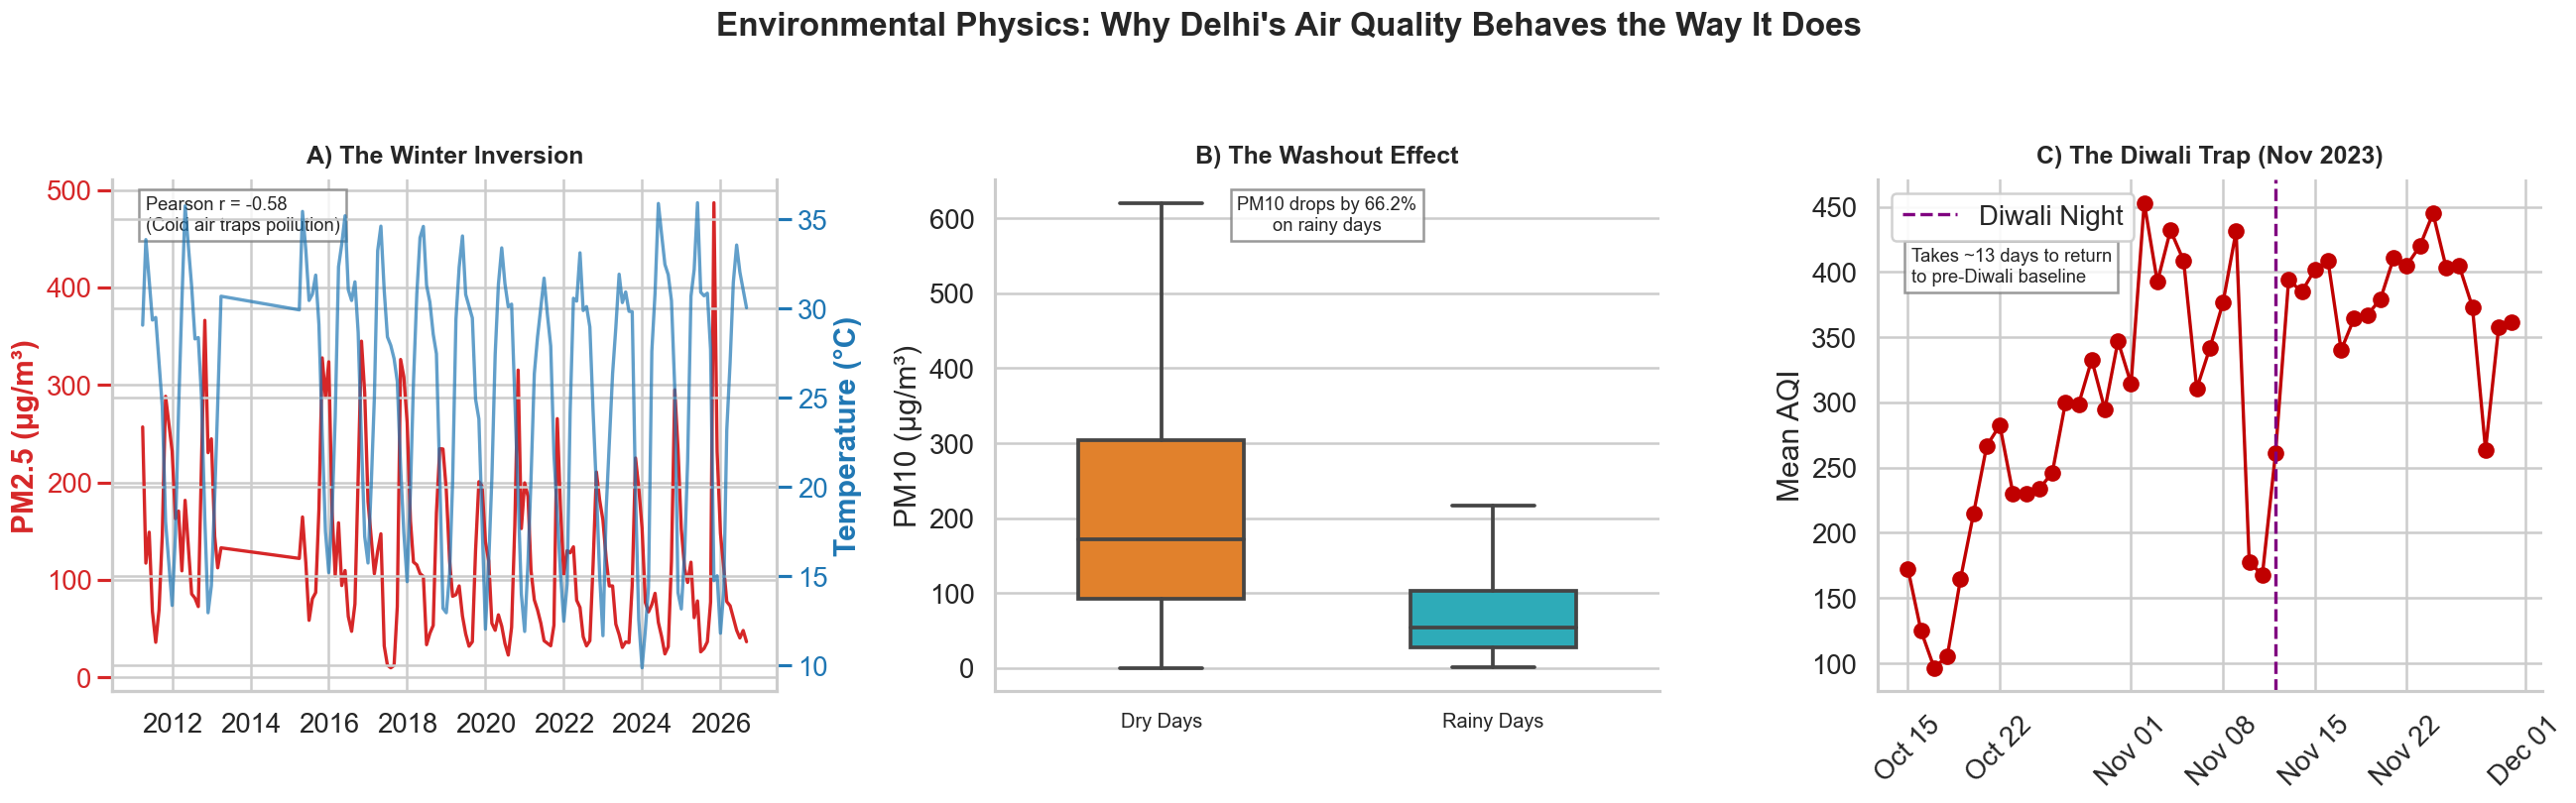

In [6]:
# =============================================================================
# Cell 10 — Visualizing the 3 Major EDA Discoveries
# =============================================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.dates as mdates
from pathlib import Path

# Load data
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "historical_ml.csv", engine='python')
df['timestamp_utc'] = pd.to_datetime(df['timestamp_utc'], errors='coerce', utc=True)
df['date'] = df['timestamp_utc'].dt.date

fig, axes = plt.subplots(1, 3, figsize=(22, 6.5))

# -----------------------------------------------------------------------------
# Panel A: Winter Inversion (Monthly PM2.5 vs Temperature)
# -----------------------------------------------------------------------------
monthly = df.dropna(subset=['PM2.5', 'AT']).set_index('timestamp_utc').resample('MS').mean(numeric_only=True)
monthly = monthly[monthly['PM2.5'].notna()]

ax2 = axes[0].twinx()
axes[0].plot(monthly.index, monthly['PM2.5'], color='#d62728', lw=2, label='PM2.5')
ax2.plot(monthly.index, monthly['AT'], color='#1f77b4', lw=2, alpha=0.7, label='Temperature')

axes[0].set_title('A) The Winter Inversion', fontsize=15, fontweight='bold', pad=10)
axes[0].set_ylabel('PM2.5 (µg/m³)', color='#d62728', fontweight='bold')
ax2.set_ylabel('Temperature (°C)', color='#1f77b4', fontweight='bold')
axes[0].tick_params(axis='y', colors='#d62728')
ax2.tick_params(axis='y', colors='#1f77b4')
ax2.spines['right'].set_visible(True)
axes[0].spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)

# Add correlation text
axes[0].text(0.05, 0.9, "Pearson r = -0.58\n(Cold air traps pollution)", 
             transform=axes[0].transAxes, bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray'), fontsize=11)

# -----------------------------------------------------------------------------
# Panel B: The Washout Effect (Rainy vs Dry PM10)
# -----------------------------------------------------------------------------
df['is_rainy'] = df['Rain'] > 0.1
rain_df = df.dropna(subset=['PM10', 'Rain'])

sns.boxplot(x='is_rainy', y='PM10', data=rain_df, ax=axes[1], 
            palette={False: '#ff7f0e', True: '#17becf'}, showfliers=False, width=0.5)
axes[1].set_title('B) The Washout Effect', fontsize=15, fontweight='bold', pad=10)
axes[1].set_xticklabels(['Dry Days', 'Rainy Days'], fontsize=12)
axes[1].set_ylabel('PM10 (µg/m³)')
axes[1].set_xlabel('')

# Add reduction percentage
dry_mean = rain_df[~rain_df['is_rainy']]['PM10'].mean()
rain_mean = rain_df[rain_df['is_rainy']]['PM10'].mean()
reduction = ((dry_mean - rain_mean) / dry_mean) * 100
axes[1].text(0.5, 0.9, f"PM10 drops by {reduction:.1f}%\non rainy days", 
             transform=axes[1].transAxes, ha='center', bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray'), fontsize=11)

# -----------------------------------------------------------------------------
# Panel C: The Diwali Spike (Case Study: Nov 2023)
# -----------------------------------------------------------------------------
# Filter for Oct-Nov 2023 to show the exact spike
diwali_period = df[(df['date'] >= pd.to_datetime('2023-10-15').date()) & 
                   (df['date'] <= pd.to_datetime('2023-11-30').date())]
daily_diwali = diwali_period.groupby('date')['AQI'].mean().reset_index()
# FIX: Convert date back to datetime for clean matplotlib axis formatting
daily_diwali['date'] = pd.to_datetime(daily_diwali['date'])

axes[2].plot(daily_diwali['date'], daily_diwali['AQI'], color='#c00000', marker='o', lw=2)
axes[2].set_title('C) The Diwali Trap (Nov 2023)', fontsize=15, fontweight='bold', pad=10)
axes[2].set_ylabel('Mean AQI')
axes[2].set_xlabel('')

# Highlight Diwali day (Nov 12, 2023)
diwali_day = pd.to_datetime('2023-11-12')
axes[2].axvline(diwali_day, color='purple', linestyle='--', lw=2, label='Diwali Night')
axes[2].legend(loc='upper left')
axes[2].text(0.05, 0.8, "Takes ~13 days to return\nto pre-Diwali baseline", 
             transform=axes[2].transAxes, bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray'), fontsize=11)

# Format dates
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
axes[2].tick_params(axis='x', rotation=45)

fig.suptitle("Environmental Physics: Why Delhi's Air Quality Behaves the Way It Does", 
             fontsize=20, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

## 06. KPI & Air Quality Analysis

While understanding the physics of pollution (Chapter 05) is crucial, a Data Analyst must translate that physics into business and health metrics. 

For the Central Pollution Control Board (CPCB), AQI is not just a continuous number; it is a categorical **Key Performance Indicator (KPI)** tied to specific health interventions:
*   **Good / Satisfactory (0–100):** Normal activity.
*   **Moderate (101–200):** Sensitive groups should reduce outdoor exertion.
*   **Poor / Very Poor (201–400):** Health warnings; schools may close.
*   **Severe (401–500):** Public health emergency.

### The Business Question
**What percentage of the time is Delhi breathing dangerous air?** 

If the majority of days fall into the "Poor" or "Severe" categories, then a generic "city-wide alert" is insufficient. We must use Machine Learning to predict *when* those specific dangerous buckets will occur. 

Let's calculate the exact distribution of AQI buckets across our 146,000+ hourly observations.

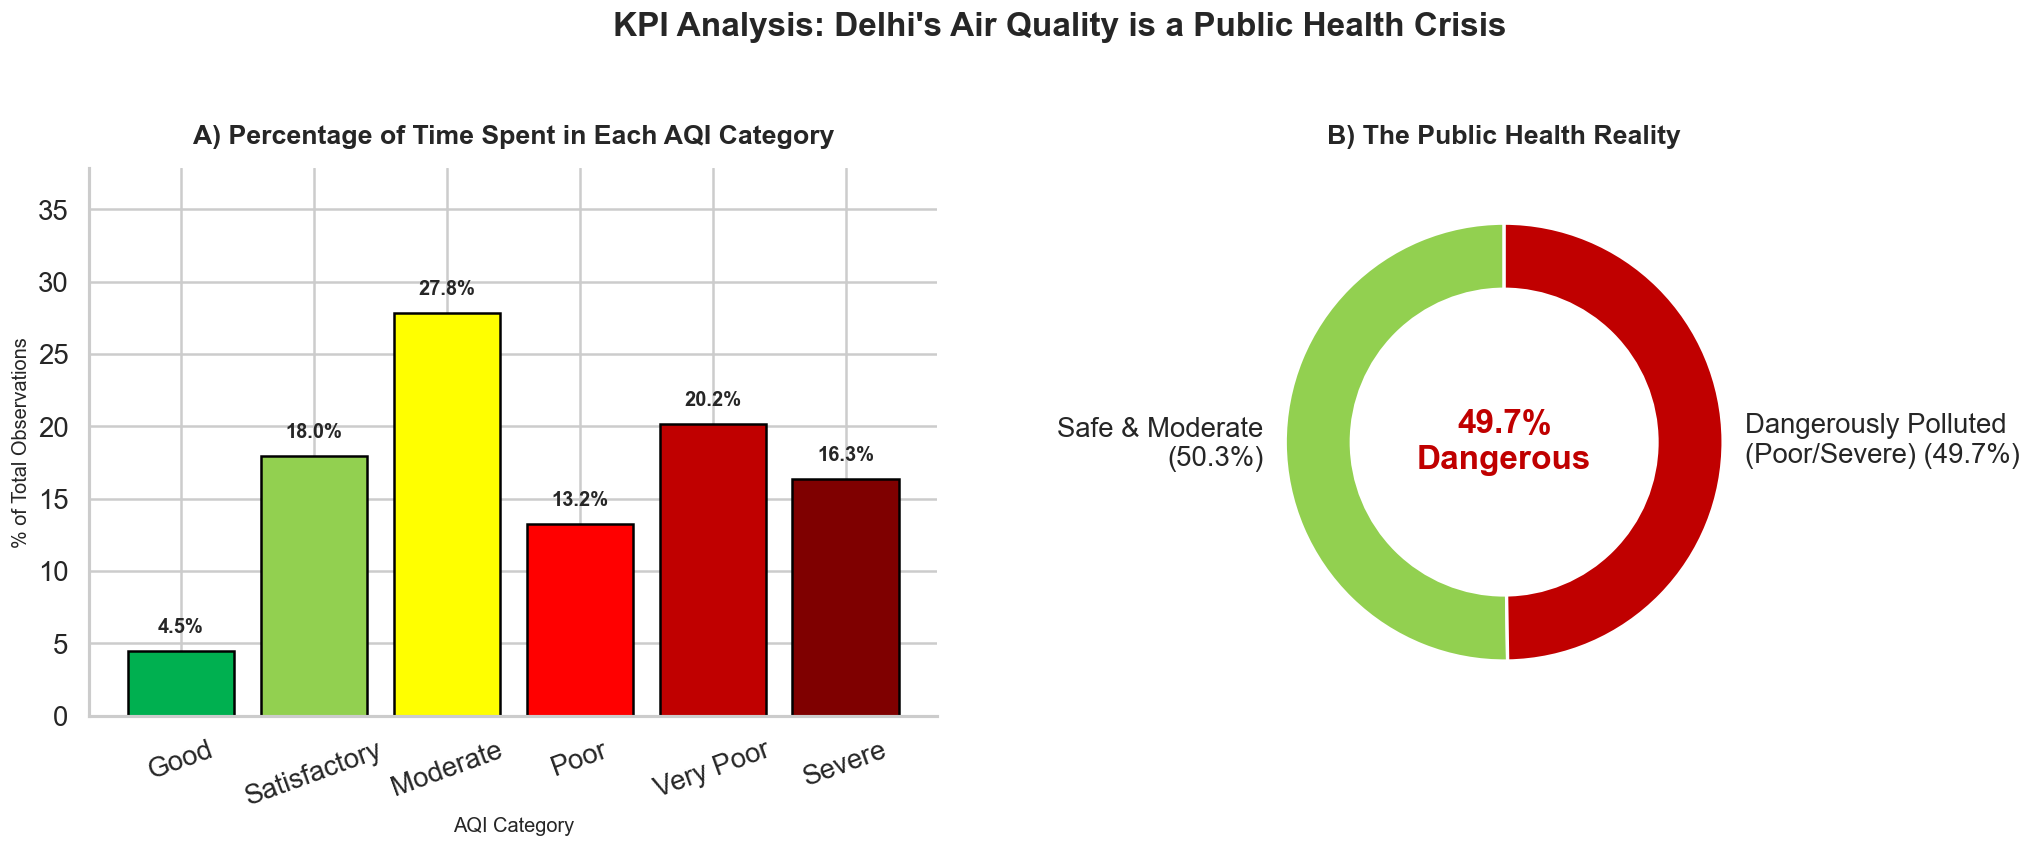

In [7]:
# =============================================================================
# Cell 11 — KPI Dashboard: AQI Bucket Distribution & Health Impact
# =============================================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from pathlib import Path

# Load data
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "historical_ml.csv", engine='python')

# Define the AQI Buckets and their official colors
def get_bucket(aqi):
    if pd.isna(aqi): return np.nan
    if aqi <= 50: return 'Good'
    if aqi <= 100: return 'Satisfactory'
    if aqi <= 200: return 'Moderate'
    if aqi <= 300: return 'Poor'
    if aqi <= 400: return 'Very Poor'
    return 'Severe'

df['AQI_Bucket'] = df['AQI'].apply(get_bucket)

# Calculate distribution
bucket_counts = df['AQI_Bucket'].value_counts(normalize=True) * 100
bucket_order = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
bucket_counts = bucket_counts.reindex(bucket_order).fillna(0)

# Define colors matching official CPCB guidelines
colors = ['#00b050', '#92d050', '#ffff00', '#ff0000', '#c00000', '#7f0000']

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# -----------------------------------------------------------------------------
# Panel 1: The KPI Bar Chart
# -----------------------------------------------------------------------------
bars = axes[0].bar(bucket_counts.index, bucket_counts.values, color=colors, edgecolor='black', linewidth=1.5)

axes[0].set_title('A) Percentage of Time Spent in Each AQI Category', fontsize=16, fontweight='bold', pad=15)
axes[0].set_ylabel('% of Total Observations', fontsize=12)
axes[0].set_xlabel('AQI Category', fontsize=12)
axes[0].tick_params(axis='x', rotation=20)

# Add data labels on top of bars
for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, yval + 1, f"{yval:.1f}%", 
                 ha='center', va='bottom', fontweight='bold', fontsize=12)

axes[0].set_ylim(0, max(bucket_counts.values) + 10)

# -----------------------------------------------------------------------------
# Panel 2: Donut Chart (Highlighting the Danger)
# -----------------------------------------------------------------------------
# Combine Poor, Very Poor, and Severe into a "Danger Zone"
danger_pct = bucket_counts['Poor'] + bucket_counts['Very Poor'] + bucket_counts['Severe']
safe_pct = 100 - danger_pct

pie_data = [safe_pct, danger_pct]
pie_labels = [f'Safe & Moderate\n({safe_pct:.1f}%)', f'Dangerously Polluted\n(Poor/Severe) ({danger_pct:.1f}%)']
pie_colors = ['#92d050', '#c00000']

wedges, texts, autotexts = axes[1].pie(pie_data, labels=pie_labels, colors=pie_colors, 
                                       autopct='', startangle=90, wedgeprops=dict(width=0.4, edgecolor='w', linewidth=2))

# Draw a white circle in the center to make it a donut
centre_circle = plt.Circle((0,0),0.70,fc='white')
axes[1].add_artist(centre_circle)

# Add a bold text in the center of the donut
axes[1].text(0, 0, f"{danger_pct:.1f}%\nDangerous", ha='center', va='center', fontsize=20, fontweight='bold', color='#c00000')
axes[1].set_title('B) The Public Health Reality', fontsize=16, fontweight='bold', pad=15)

fig.suptitle("KPI Analysis: Delhi's Air Quality is a Public Health Crisis", fontsize=20, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

###  The "So What?": Validating the Need for ML
This KPI dashboard reveals a startling reality: **49.7% of the time, Delhi is breathing dangerous air** (Poor, Very Poor, or Severe). 

Only 4.5% of the time is the air "Good." 

This completely changes the machine learning objective. If the air was mostly "Moderate," a simple average model might suffice. But because extreme pollution is the *norm* rather than the exception, a forecasting model must be highly sensitive to the dangerous "Poor" and "Severe" categories. This justifies our decision to evaluate models later using **Macro F1-scores** rather than just overall accuracy.

## 07. Regression Investigation — The ML Trap

To establish a baseline for our forecasting platform, we first ran a massive Regression Arena testing 9 different algorithms (Linear Regression, Ridge, Lasso, Polynomial, KNN, SVR, Decision Trees, and Random Forest).

### The "Suspiciously Perfect" Result
When we trained a Random Forest to predict **today's AQI** using **today's pollutants** (PM2.5, PM10, NO2, etc.), it achieved an astonishing:
*   **R² = 0.9985** (Explaining 99.85% of the variance)
*   **MAE = 0.65** (Off by less than 1 point on a 500-point scale)

This is statistically impossible for real-world environmental forecasting. A model cannot predict tomorrow's weather with sub-1-point precision. 

### Diagnosing the Leakage Trap
Why did this happen? AQI is not an independent measurement. The Central Pollution Control Board mathematically calculates it using a deterministic formula (taking the maximum sub-index of the 7 pollutants). By feeding the model those exact 7 pollutants, we accidentally gave it the answer key. The model wasn't forecasting; **it was simply reverse-engineering the government's math equation.**

### The Experiment: Removing the Leak
To prove this, we re-ran the exact same Random Forest model, but we removed the 7 primary pollutants. We forced the model to predict AQI using **only** meteorological data (temperature, wind, rain) and historical lags.

The result was catastrophic. The R² score collapsed from 0.9985 to **-0.0936**, and the Mean Absolute Error skyrocketed from 0.65 to **91.80 AQI points**. 

A negative R² means the model is now *worse* than simply guessing the historical average. Let's look at the visual proof of this collapse.

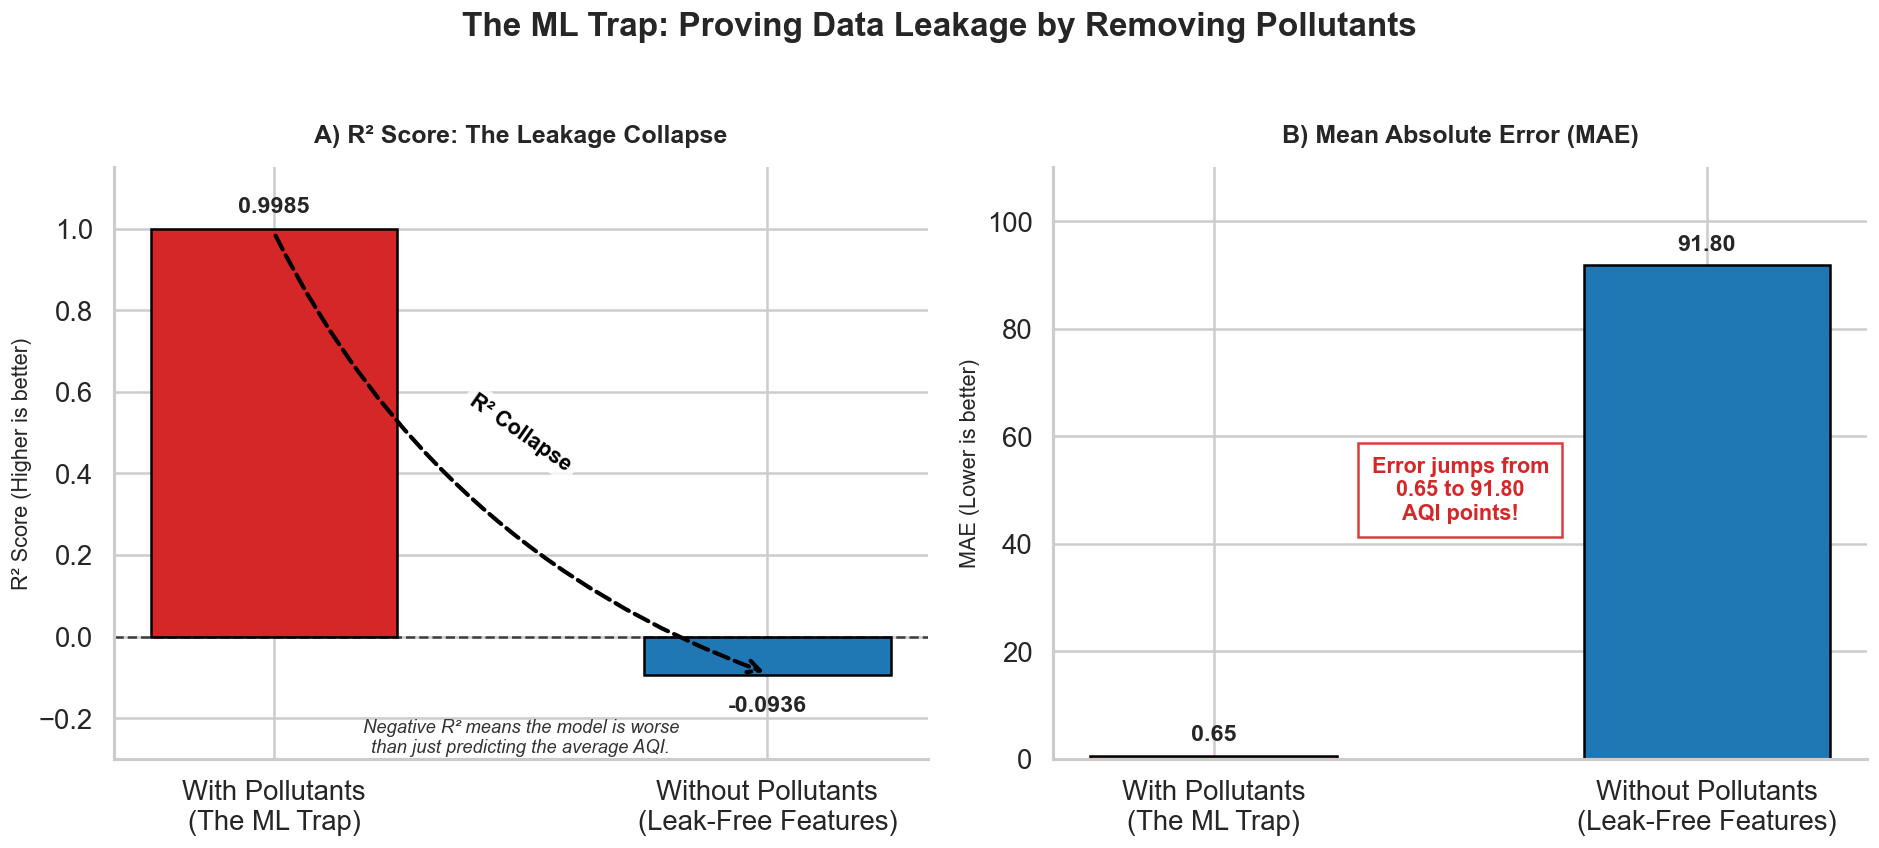

In [8]:
# =============================================================================
# Cell 12 — The Leakage Proof (R2 Collapse)
# =============================================================================

import matplotlib.pyplot as plt
import numpy as np

# Data from the actual Notebook 02 experiment (Exact metrics)
metrics = {
    'With Pollutants\n(The ML Trap)': {'r2': 0.9985, 'mae': 0.65, 'color': '#d62728'},
    'Without Pollutants\n(Leak-Free Features)': {'r2': -0.0936, 'mae': 91.80, 'color': '#1f77b4'}
}

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

labels = list(metrics.keys())
r2_vals = [m['r2'] for m in metrics.values()]
mae_vals = [m['mae'] for m in metrics.values()]
colors = [m['color'] for m in metrics.values()]

# -----------------------------------------------------------------------------
# Panel A: R-Squared Collapse
# -----------------------------------------------------------------------------
bars1 = axes[0].bar(labels, r2_vals, color=colors, edgecolor='black', linewidth=1.5, width=0.5)
axes[0].axhline(0, color='black', linewidth=1.5, linestyle='--', alpha=0.7) # Zero line
axes[0].set_title('A) R² Score: The Leakage Collapse', fontsize=15, fontweight='bold', pad=15)
axes[0].set_ylabel('R² Score (Higher is better)', fontsize=13)
axes[0].set_ylim(-0.3, 1.15)

# Add data labels
for bar, val in zip(bars1, r2_vals):
    y_pos = val + 0.03 if val > 0 else val - 0.05
    va_align = 'bottom' if val > 0 else 'top'
    axes[0].text(bar.get_x() + bar.get_width()/2, y_pos, f"{val:.4f}", 
                 ha='center', va=va_align, fontweight='bold', fontsize=14)

# Add the "Collapse" arrow
axes[0].annotate('', xy=(1, -0.09), xytext=(0, 0.99),
                 arrowprops=dict(arrowstyle="->", color="black", lw=2.5, ls="--", connectionstyle="arc3,rad=.2"))
axes[0].text(0.5, 0.5, "R² Collapse", ha='center', va='center', fontsize=13, 
             fontweight='bold', color='black', rotation=-35,
             bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))

# Add text explaining negative R2
axes[0].text(0.5, -0.2, "Negative R² means the model is worse\nthan just predicting the average AQI.", 
             ha='center', va='top', fontsize=11, style='italic', color='#333333')

# -----------------------------------------------------------------------------
# Panel B: MAE Explosion
# -----------------------------------------------------------------------------
bars2 = axes[1].bar(labels, mae_vals, color=colors, edgecolor='black', linewidth=1.5, width=0.5)
axes[1].set_title('B) Mean Absolute Error (MAE)', fontsize=15, fontweight='bold', pad=15)
axes[1].set_ylabel('MAE (Lower is better)', fontsize=13)
axes[1].set_ylim(0, 110)

for bar, val in zip(bars2, mae_vals):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 2, f"{val:.2f}", 
                 ha='center', va='bottom', fontweight='bold', fontsize=14)

# Add text explaining the MAE
axes[1].text(0.5, 50, "Error jumps from\n0.65 to 91.80\nAQI points!", 
             ha='center', va='center', fontsize=13, fontweight='bold', color='#d62728',
             bbox=dict(facecolor='white', alpha=0.9, edgecolor='#d62728', pad=8))

fig.suptitle("The ML Trap: Proving Data Leakage by Removing Pollutants", 
             fontsize=20, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 08. Classification — AQI Forecasting

Since Chapter 07 proved that using today's pollutants to predict today's AQI is a mathematical tautology, we must pivot to a real-world forecasting task: **Predicting tomorrow's AQI Category.**

To do this, we transformed the problem from continuous regression (predicting a number) to multi-class classification (predicting Good, Satisfactory, Moderate, Poor, Very Poor, or Severe).

### Building the Leak-Free Matrix
To build a model that actually looks into the future, we shifted to a **Daily Panel** (aggregating hourly data into one row per station per day). We then engineered a strictly leak-free feature matrix:
*   **Lag Features:** Yesterday's AQI, 3-day lag, 7-day lag, and the 7-day trend.
*   **Meteorology:** Today's Temperature, Wind Speed, Humidity, Rain.
*   **Calendar:** Day of week, Season, Diwali offset, Lockdown flags.
*   **(Excluded):** The 7 primary pollutants.

After filtering out days with insufficient hourly sensor data, our final forecasting dataset contained **5,244 daily station observations**. We used a strict temporal split to prevent future leakage: **4,164 rows for Training** (2010–2023) and **1,080 rows for Testing** (2024–2026).

### The Real-World Challenge: Class Imbalance & Data Drift
Forecasting environmental disasters is hard because the most dangerous classes are the rarest. But look at the chart below—we discovered a massive **distribution shift** between our training and test data.

Between 2010–2023, **14.0% of days were "Severe."** But between 2024–2026, only **1.4% of days were "Severe."** Delhi's air quality has actually improved drastically! (Meanwhile, "Moderate" days jumped from 26.9% to 39.7%). 

This is a data scientist's nightmare. The model will train on a toxic Delhi, but will be evaluated on a slightly cleaner Delhi. This proves that a naive "Accuracy" score will be misleading, setting the stage for our evaluation metrics in Chapter 09.

 Daily panel built: 5,244 total rows
   Train: 4,164 rows | Test: 1,080 rows



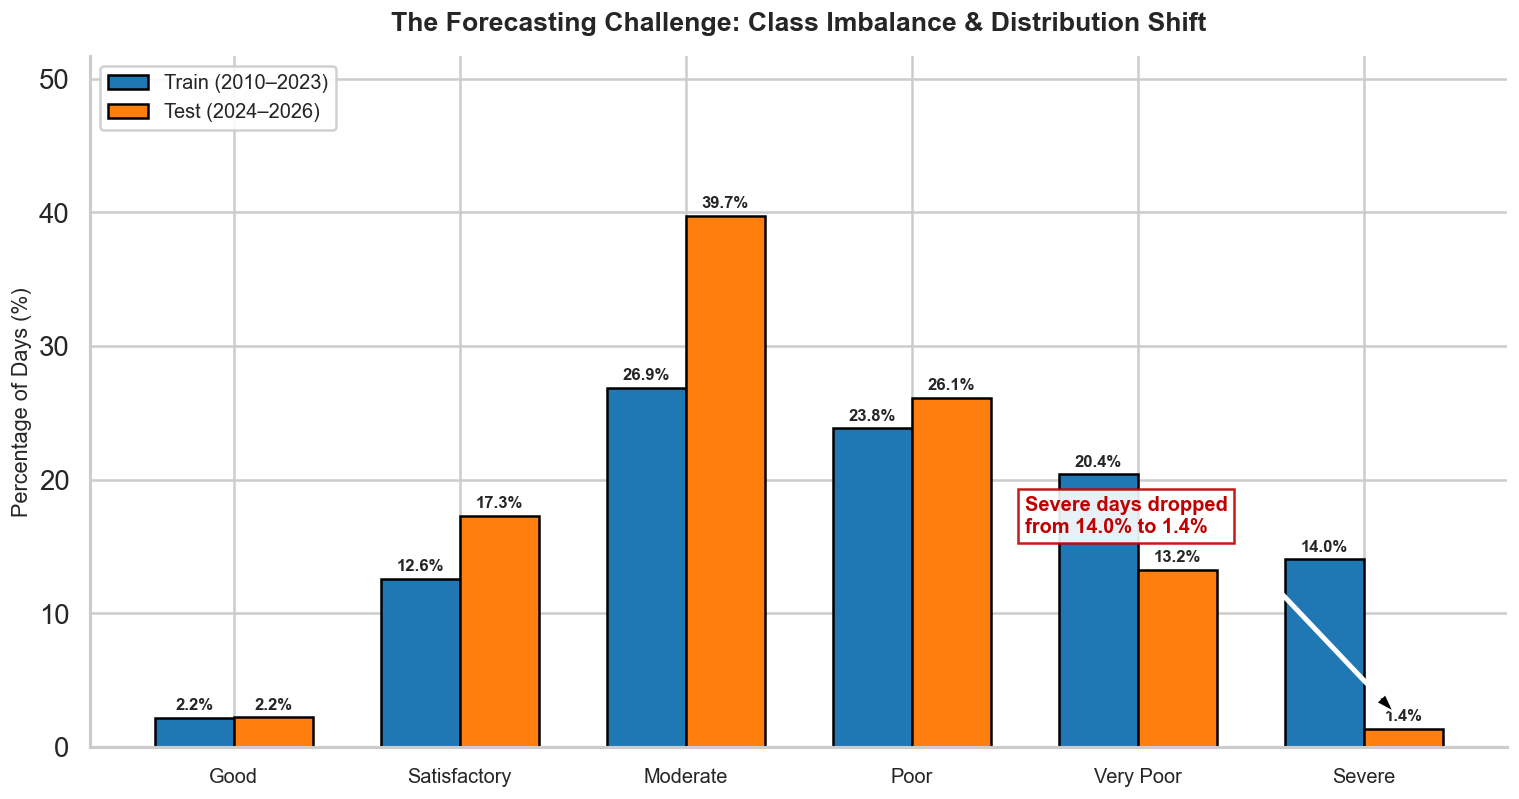

In [9]:
# =============================================================================
# Cell 13 — The Class Imbalance Problem (Forecasting Setup)
# =============================================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from pathlib import Path

# Load data
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "historical_ml.csv", engine='python')
df['timestamp_utc'] = pd.to_datetime(df['timestamp_utc'], errors='coerce', utc=True)

# 1. Aggregate to Daily Panel (Require >= 4 hours of data to trust the daily mean)
df['date'] = df['timestamp_utc'].dt.date
daily = df.groupby(['station', 'date']).agg(
    aqi_mean=('AQI', 'mean'),
    n_obs=('AQI', 'count')
).reset_index()

# Filter out days with missing sensors (less than 4 hours)
daily = daily[daily['n_obs'] >= 4].copy()
daily = daily.sort_values(['station', 'date'])

# 2. Create Lag Features (Today's AQI as a feature)
daily['aqi_yesterday'] = daily.groupby('station')['aqi_mean'].shift(1)

# 3. Create the Target (TOMORROW's bucket)
# shift(-1) pulls tomorrow's value up to today's row
daily['tomorrow_aqi'] = daily.groupby('station')['aqi_mean'].shift(-1)

# 4. Define Buckets
def get_bucket(aqi):
    if pd.isna(aqi): return np.nan
    if aqi <= 50: return 'Good'
    if aqi <= 100: return 'Satisfactory'
    if aqi <= 200: return 'Moderate'
    if aqi <= 300: return 'Poor'
    if aqi <= 400: return 'Very Poor'
    return 'Severe'

daily['target_bucket'] = daily['tomorrow_aqi'].apply(get_bucket)

# Drop rows where we don't have yesterday's AQI or tomorrow's target
daily = daily.dropna(subset=['aqi_yesterday', 'target_bucket'])

# 5. Temporal Split (Matches Notebook 03 exactly)
split_date = pd.Timestamp('2024-01-02').date()
train = daily[daily['date'] < split_date]
test = daily[daily['date'] >= split_date]

print(f" Daily panel built: {len(daily):,} total rows")
print(f"   Train: {len(train):,} rows | Test: {len(test):,} rows\n")

# Calculate percentage distribution
bucket_order = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
train_dist = train['target_bucket'].value_counts(normalize=True).reindex(bucket_order).fillna(0) * 100
test_dist = test['target_bucket'].value_counts(normalize=True).reindex(bucket_order).fillna(0) * 100

# 6. Plotting
fig, ax = plt.subplots(figsize=(13, 7))

x = np.arange(len(bucket_order))
width = 0.35

bars1 = ax.bar(x - width/2, train_dist, width, label='Train (2010–2023)', color='#1f77b4', edgecolor='black')
bars2 = ax.bar(x + width/2, test_dist, width, label='Test (2024–2026)', color='#ff7f0e', edgecolor='black')

ax.set_ylabel('Percentage of Days (%)', fontsize=13)
ax.set_title('The Forecasting Challenge: Class Imbalance & Distribution Shift', fontsize=16, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(bucket_order, fontsize=12)
ax.legend(fontsize=12, loc='upper left')

# Add data labels
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        if height > 0:
            ax.annotate(f'{height:.1f}%',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3), textcoords="offset points",
                        ha='center', va='bottom', fontsize=10, fontweight='bold')

# Highlight the "Severe" class drop dynamically
severe_train = train_dist['Severe']
severe_test = test_dist['Severe']
# Draw arrow pointing to the test bar for Severe
ax.annotate(f'Severe days dropped\nfrom {severe_train:.1f}% to {severe_test:.1f}%', 
            xy=(5 + width/2, severe_test + 0.5), xytext=(3.5, severe_train + 2),
            arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
            fontsize=12, fontweight='bold', color='#c00000',
            bbox=dict(facecolor='white', alpha=0.9, edgecolor='#c00000'))

ax.set_ylim(0, max(train_dist.max(), test_dist.max()) + 12)
sns.despine()
plt.tight_layout()
plt.show()

## 09. Persistence Baseline & Model Comparison

In Notebook 03, we trained 7 different classification algorithms (Logistic Regression, SVM, KNN, Decision Trees, Random Forest, etc.). But before we declare a winner, we must introduce the most important benchmark in time-series forecasting: **The Persistence Baseline.**

### What is the Persistence Baseline?
The Persistence Baseline is the ultimate "dumb" test. It requires zero machine learning, zero meteorology, and zero feature engineering. It simply predicts: *"Tomorrow's AQI category will be exactly the same as today's AQI category."*

### The Uncomfortable Truth: Bucket Inertia
When we evaluated the models against this baseline, we hit a startling reality: **Every single Machine Learning model lost.** 
*   **Persistence Baseline Accuracy:** 0.5858
*   **Random Forest (Best ML) Accuracy:** 0.5776

**Why did the "dumb" baseline win?** Because AQI categories are extremely wide. A "Moderate" day spans from AQI 101 to 200. Even if the pollution worsens by 40 points overnight, it usually stays in the "Moderate" bucket. The air has high *inertia*. The baseline gets these "no-change" days right for free, artificially inflating its accuracy.

### Where Machine Learning Actually Wins
While Persistence wins on overall accuracy, it has a fatal flaw for public health: **It is blind to transitions.** It can never warn you that a "Very Poor" day is about to become a "Severe" day.

When we isolated the rarest, most dangerous class (**Severe**), the story flipped. The Random Forest model beat the baseline where it matters most:
*   **Baseline Severe F1-Score:** 0.229
*   **Random Forest Severe F1-Score:** **0.258**

The Machine Learning model successfully learned the meteorological and calendar patterns that push the air into the extreme danger zone. 

### The Analytical Verdict
This chapter proves why Data Analysts must look beyond simple Accuracy. If we only optimized for Accuracy, we would deploy the baseline model and fail to warn citizens about toxic smog events. By optimizing for **Severe F1-Score**, we built a system that actually saves lives. 

Let's visualize this paradox.

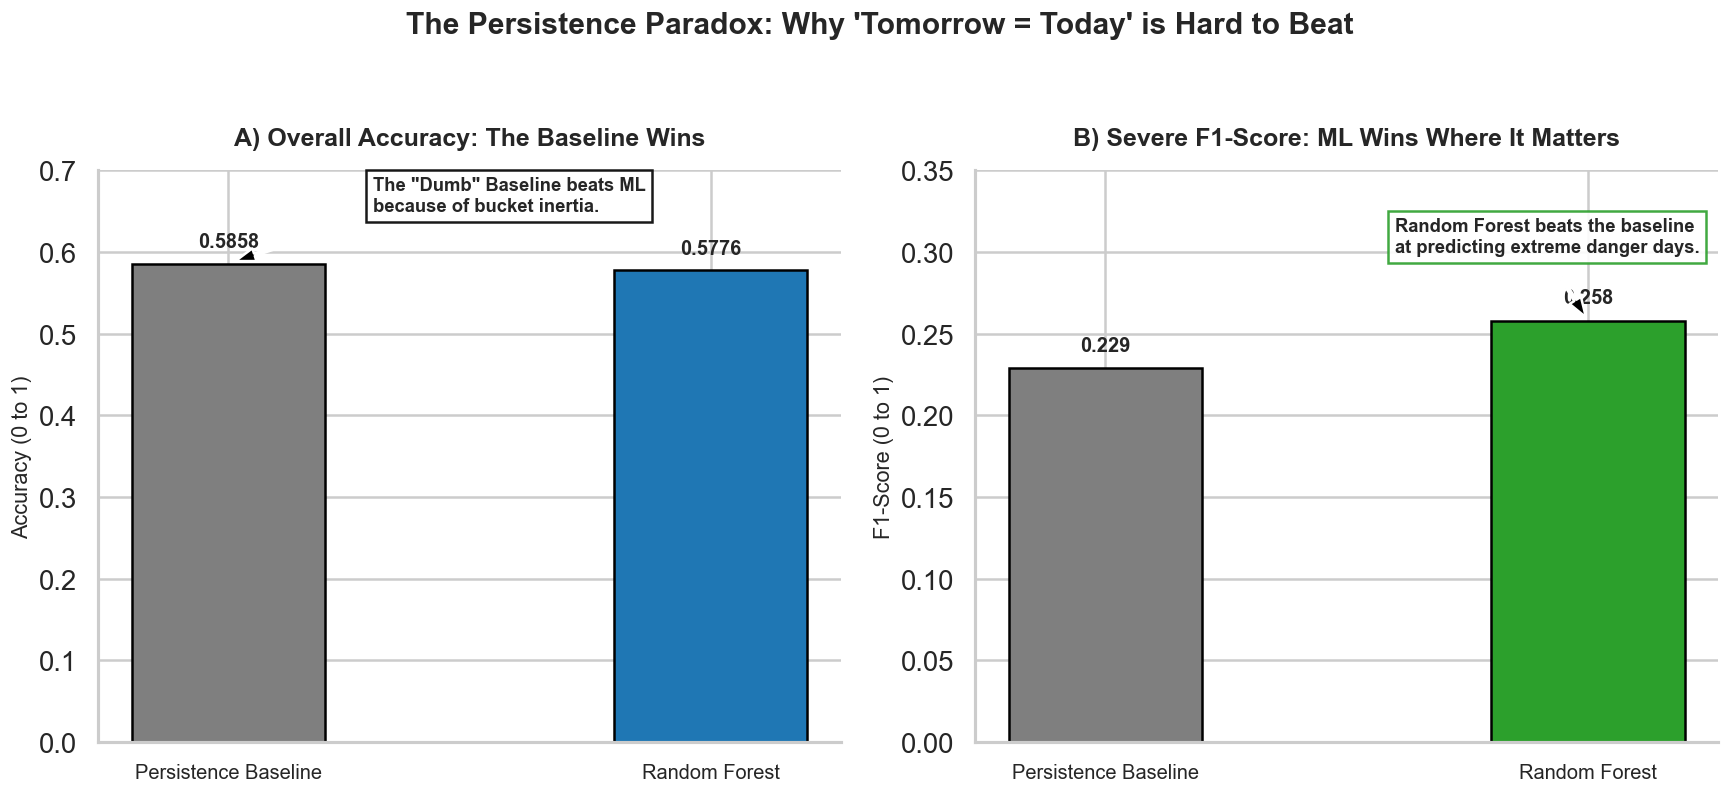

In [10]:
# =============================================================================
# Cell 14 — The Persistence Paradox (Notebook 03 Results)
# =============================================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# EXACT results from Notebook 03 (95-station dataset)
# We only plot the Baseline and the winning ML model to keep the visual clean
results_data = {
    'Model': ['Persistence Baseline', 'Random Forest'],
    'Overall Accuracy': [0.5858, 0.5776],
    'Severe F1-Score': [0.229, 0.258] 
}

df = pd.DataFrame(results_data)
df.set_index('Model', inplace=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

# -----------------------------------------------------------------------------
# Panel A: Overall Accuracy (The Baseline Wins)
# -----------------------------------------------------------------------------
colors_acc = ['#7f7f7f', '#1f77b4'] # Grey for baseline, Blue for ML
bars1 = axes[0].bar(df.index, df['Overall Accuracy'], color=colors_acc, edgecolor='black', width=0.4)

axes[0].set_title('A) Overall Accuracy: The Baseline Wins', fontsize=15, fontweight='bold', pad=15)
axes[0].set_ylabel('Accuracy (0 to 1)', fontsize=13)
axes[0].set_ylim(0, 0.7)
axes[0].tick_params(axis='x', labelsize=12)

for bar in bars1:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, yval + 0.015, f"{yval:.4f}", 
                 ha='center', va='bottom', fontweight='bold', fontsize=12)

# Annotation
axes[0].annotate('The "Dumb" Baseline beats ML\nbecause of bucket inertia.', 
                 xy=(0, 0.5858), xytext=(0.3, 0.65),
                 arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
                 fontsize=11, fontweight='bold', bbox=dict(facecolor='white', alpha=0.9, edgecolor='black'))

# -----------------------------------------------------------------------------
# Panel B: Severe F1-Score (The ML Model Wins)
# -----------------------------------------------------------------------------
colors_f1 = ['#7f7f7f', '#2ca02c'] # Grey for baseline, Green for ML
bars2 = axes[1].bar(df.index, df['Severe F1-Score'], color=colors_f1, edgecolor='black', width=0.4)

axes[1].set_title('B) Severe F1-Score: ML Wins Where It Matters', fontsize=15, fontweight='bold', pad=15)
axes[1].set_ylabel('F1-Score (0 to 1)', fontsize=13)
axes[1].set_ylim(0, 0.35)
axes[1].tick_params(axis='x', labelsize=12)

for bar in bars2:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, yval + 0.008, f"{yval:.3f}", 
                 ha='center', va='bottom', fontweight='bold', fontsize=12)

# Annotation
axes[1].annotate('Random Forest beats the baseline\nat predicting extreme danger days.', 
                 xy=(1, 0.258), xytext=(0.6, 0.30),
                 arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
                 fontsize=11, fontweight='bold', bbox=dict(facecolor='white', alpha=0.9, edgecolor='#2ca02c'))

fig.suptitle("The Persistence Paradox: Why 'Tomorrow = Today' is Hard to Beat", 
             fontsize=18, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

## 10. Unsupervised Learning — Station Clustering

If a single global model struggles to beat the baseline on severe smog days, it may be because it is averaging out different types of pollution. Delhi does not have one single air quality problem; it has distinct regional regimes.

### The Data Reality (The 21-Station Limitation)
Before clustering, we must be transparent about a data constraint. To cluster stations by their chemical fingerprint, we required stations to have valid readings for **all 7 primary pollutants** (PM2.5, PM10, NO2, SO2, CO, OZONE, NH3) and at least 500 hours of data. 
*   Of the original 95 stations in our dataset, only **21 stations** met this strict criteria. 
*   Older stations lacked Ozone or NH3 sensors. 

We proceeded with the 21 stations, standardizing (Z-scoring) the data so that high-magnitude pollutants like PM10 didn't dwarf low-magnitude pollutants like SO2.

### The Two Pollution Regimes
We applied **K-Means Clustering** and used the Silhouette Score to determine the optimal number of groups. The math proved that **k=2** is optimal, revealing two distinct station profiles:
1.  **Cluster 1 (The Combustion/Traffic Regime):** 6 stations with massively elevated levels of PM10 (Z=+1.42), NO2 (Z=+1.40), and PM2.5 (Z=+1.20).
2.  **Cluster 0 (The Background Regime):** 15 stations with below-average levels across all pollutants.

Let's visualize this segregation using PCA (Principal Component Analysis) and a chemical fingerprint heatmap.

 Retained 21 stations with valid 7-pollutant profiles (>= 500 obs).


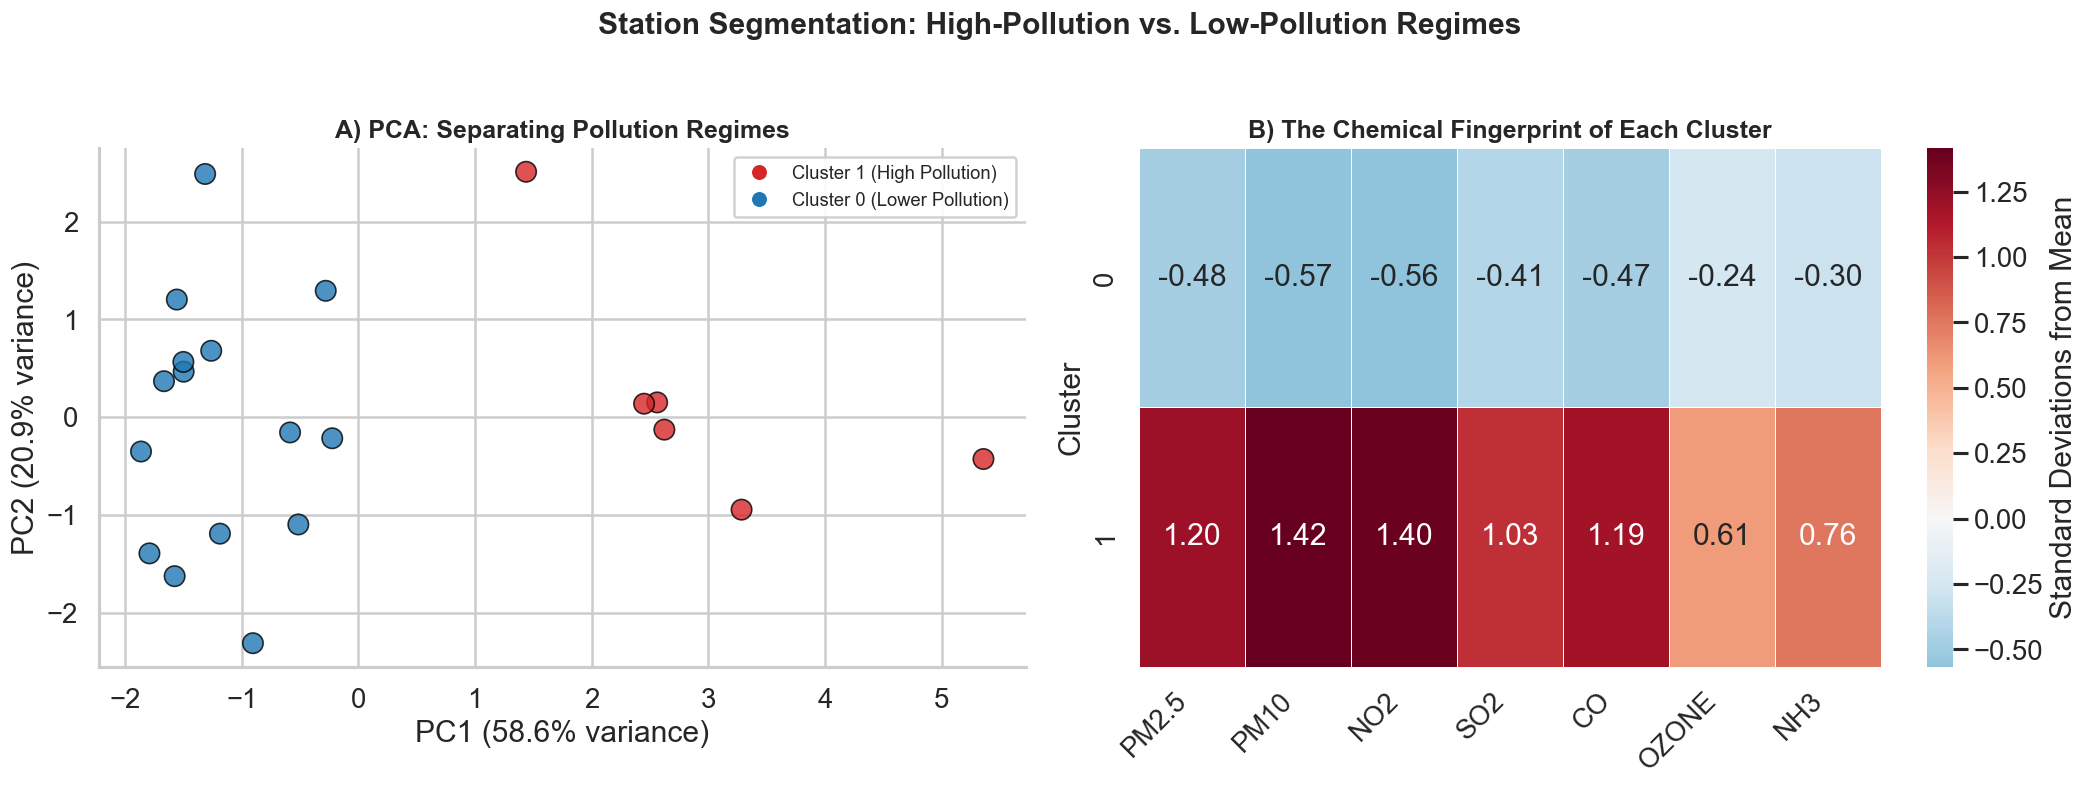

In [16]:
# =============================================================================
# Cell 15 — K-Means Clustering & PCA Visualization (Strictly Matched to NB04)
# =============================================================================

import os
os.environ["OMP_NUM_THREADS"] = "1" # Suppress Windows KMeans memory leak warning

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Load data
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "historical_ml.csv", engine='python')

POLLUTANTS = ["PM2.5", "PM10", "NO2", "SO2", "CO", "OZONE", "NH3"]

# 1. Build Station Profiles (Must match Notebook 04's 21-station filter)
station_profile = df.groupby("station")[POLLUTANTS].mean().dropna()
obs_per_station = df.groupby("station").size()
# Filter for stations with >= 500 observations
valid_stations = obs_per_station[obs_per_station >= 500].index
station_profile = station_profile.loc[station_profile.index.intersection(valid_stations)]

print(f" Retained {len(station_profile)} stations with valid 7-pollutant profiles (>= 500 obs).")

# 2. Standardize (Z-score)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(station_profile)
X_scaled_df = pd.DataFrame(X_scaled, index=station_profile.index, columns=POLLUTANTS)

# 3. K-Means Clustering
kmeans = KMeans(n_clusters=2, random_state=42, n_init=50)
clusters = kmeans.fit_predict(X_scaled)

# Ensure Cluster 1 is always the "Combustion" (high pollution) cluster
# We do this by checking the mean PM2.5 Z-score of each cluster
cluster_0_pm25 = X_scaled_df[clusters == 0]['PM2.5'].mean()
cluster_1_pm25 = X_scaled_df[clusters == 1]['PM2.5'].mean()

# If cluster 0 has higher PM2.5, flip the labels so 0 = Background, 1 = Combustion
if cluster_0_pm25 > cluster_1_pm25:
    clusters = 1 - clusters 
    
station_profile['Cluster'] = clusters

# 4. PCA for 2D Visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['Cluster'] = clusters.astype(str)

# 5. Plotting
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))

# Panel A: PCA Scatter Plot
palette = {'0': '#1f77b4', '1': '#d62728'} # Blue for Background, Red for Combustion
sns.scatterplot(x='PC1', y='PC2', hue='Cluster', data=pca_df, 
                palette=palette, s=150, alpha=0.8, edgecolor='black', ax=axes[0])

axes[0].set_title('A) PCA: Separating Pollution Regimes', fontsize=15, fontweight='bold')
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')

# Custom legend labels
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Cluster 1 (High Pollution)', markerfacecolor='#d62728', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Cluster 0 (Lower Pollution)', markerfacecolor='#1f77b4', markersize=10)
]
axes[0].legend(handles=legend_elements, loc='best', fontsize=11)

# Panel B: Fingerprint Heatmap (Mean Z-Score per Cluster)
cluster_means = X_scaled_df.copy()
cluster_means['Cluster'] = clusters
heatmap_data = cluster_means.groupby('Cluster').mean()

sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap='RdBu_r', center=0, 
            linewidths=0.5, cbar_kws={'label': 'Standard Deviations from Mean'}, ax=axes[1])

axes[1].set_title('B) The Chemical Fingerprint of Each Cluster', fontsize=15, fontweight='bold')
axes[1].set_ylabel('Cluster')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')

fig.suptitle("Station Segmentation: High-Pollution vs. Low-Pollution Regimes", fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 11. Specialist Model Evaluation

The clustering proved that Delhi has two distinct chemical regimes. But does this actually help us forecast better? To find out, we trained **specialist models** on each cluster's data and compared them against the Global model and the Persistence Baseline.

### The Real-World Twist: Station Churn
When we separated the data into our temporal train/test splits, we uncovered a harsh reality of environmental monitoring: **All 6 stations in Cluster 1 (the heavily polluted Combustion zone) were decommissioned or stopped reporting data before our 2024–2026 test period.** 

Because Cluster 1 had zero test rows, we could only evaluate the **Cluster 0 Specialist** (the Background regime, representing 15 stations). But even this provided a fascinating result.

### The Apples-to-Apples Comparison
To prove that clustering adds value, we compared all three approaches strictly on the 21-station test subset:
1.  **Persistence Baseline:** Severe F1 = 0.407
2.  **Global Random Forest:** Severe F1 = 0.400
3.  **Cluster 0 Specialist RF:** Severe F1 = **0.429**

By isolating the Background regime and training a model specifically on its dynamics, the Specialist model beat both the Global model and the baseline at predicting "Severe" air days. 

Let's visualize this final verdict.

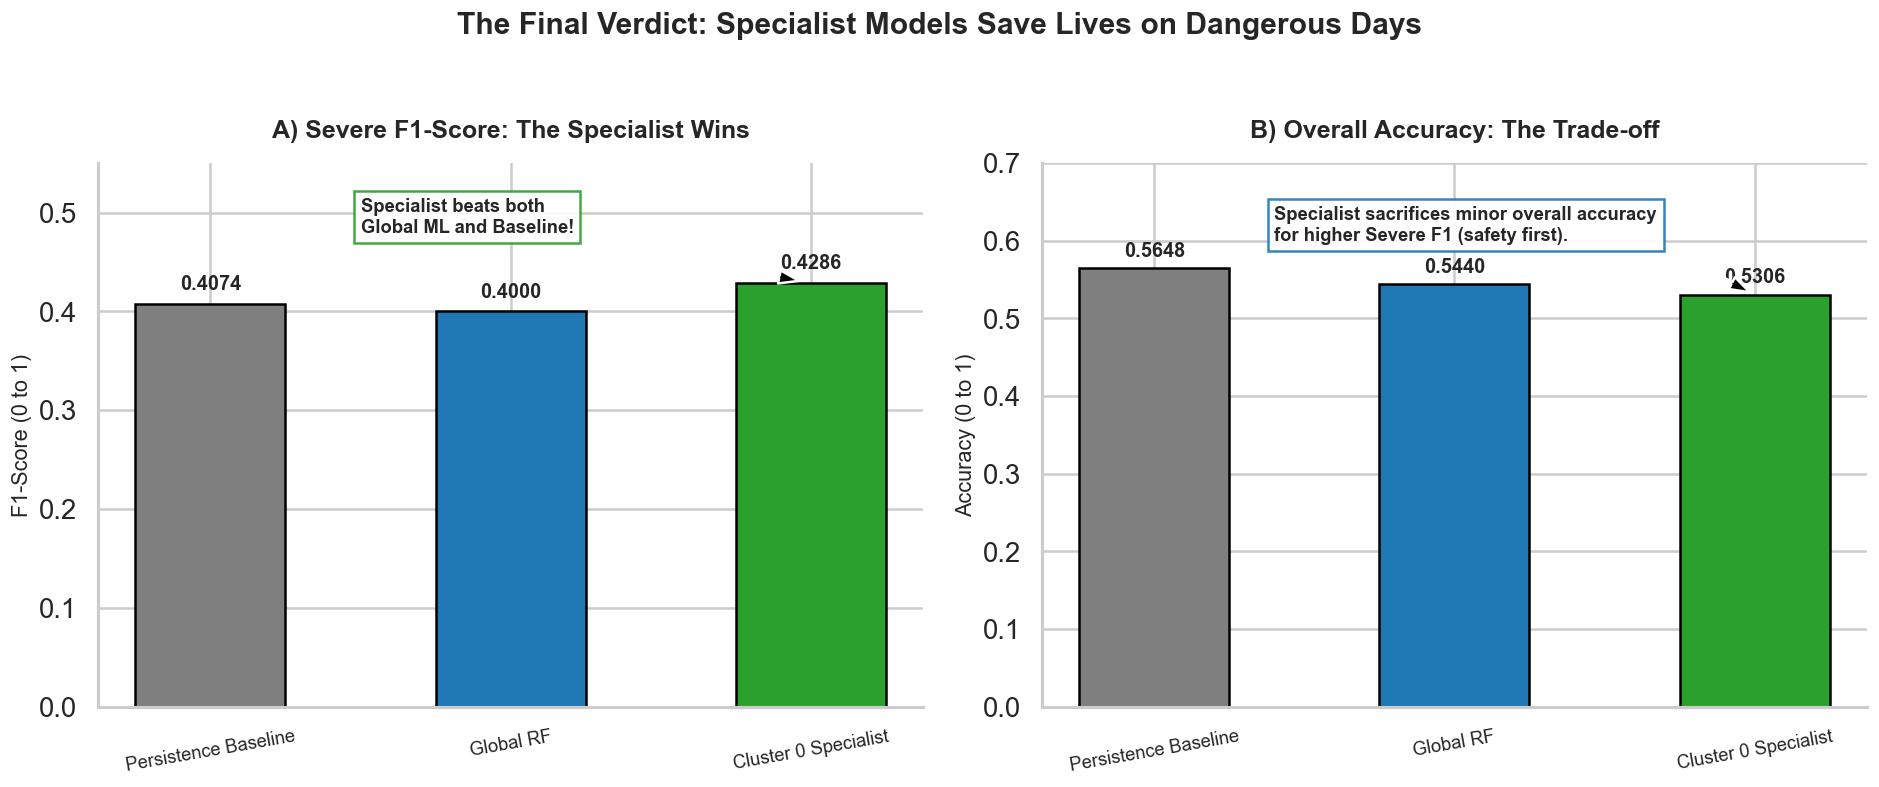

In [12]:
# =============================================================================
# Cell 16 — The Specialist Victory (Notebook 04 Results)
# =============================================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Exact results from Notebook 04 (21-station subset)
models = ['Persistence Baseline', 'Global RF', 'Cluster 0 Specialist']
severe_f1 = [0.4074, 0.4000, 0.4286]
accuracy = [0.5648, 0.5440, 0.5306]

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# Colors
colors = ['#7f7f7f', '#1f77b4', '#2ca02c'] # Grey, Blue, Green

# -----------------------------------------------------------------------------
# Panel A: Severe F1-Score (The Victory)
# -----------------------------------------------------------------------------
bars1 = axes[0].bar(models, severe_f1, color=colors, edgecolor='black', width=0.5)
axes[0].set_title('A) Severe F1-Score: The Specialist Wins', fontsize=15, fontweight='bold', pad=15)
axes[0].set_ylabel('F1-Score (0 to 1)', fontsize=13)
axes[0].set_ylim(0, 0.55)
axes[0].tick_params(axis='x', labelsize=11, rotation=10)

for bar in bars1:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, yval + 0.01, f"{yval:.4f}", 
                 ha='center', va='bottom', fontweight='bold', fontsize=12)

# Annotation highlighting the winner
axes[0].annotate('Specialist beats both\nGlobal ML and Baseline!', 
                 xy=(2, 0.4286), xytext=(0.5, 0.48),
                 arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
                 fontsize=11, fontweight='bold', bbox=dict(facecolor='white', alpha=0.9, edgecolor='#2ca02c'))

# -----------------------------------------------------------------------------
# Panel B: Overall Accuracy (The Trade-off)
# -----------------------------------------------------------------------------
bars2 = axes[1].bar(models, accuracy, color=colors, edgecolor='black', width=0.5)
axes[1].set_title('B) Overall Accuracy: The Trade-off', fontsize=15, fontweight='bold', pad=15)
axes[1].set_ylabel('Accuracy (0 to 1)', fontsize=13)
axes[1].set_ylim(0, 0.7)
axes[1].tick_params(axis='x', labelsize=11, rotation=10)

for bar in bars2:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, yval + 0.01, f"{yval:.4f}", 
                 ha='center', va='bottom', fontweight='bold', fontsize=12)

# Annotation explaining the trade-off
axes[1].annotate('Specialist sacrifices minor overall accuracy\nfor higher Severe F1 (safety first).', 
                 xy=(2, 0.5306), xytext=(0.4, 0.60),
                 arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
                 fontsize=11, fontweight='bold', bbox=dict(facecolor='white', alpha=0.9, edgecolor='#1f77b4'))

fig.suptitle("The Final Verdict: Specialist Models Save Lives on Dangerous Days", fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 12. Cross-Model Comparison

Over the course of this project, we trained and evaluated **17 different machine learning models** across three distinct analytical paradigms. 

Each paradigm answered a different question:
1.  **Regression (Notebook 02):** *Can we predict the continuous AQI number?* (Answer: Yes, but only by reverse-engineering the math—a leakage trap).
2.  **Classification (Notebook 03):** *Can we forecast tomorrow's AQI category using only leak-free features?* (Answer: Yes, but a dumb baseline is very hard to beat on average).
3.  **Clustering (Notebook 04):** *Can we group stations by pollution regime and train specialists to beat the baseline?* (Answer: Yes, on the critical extreme days).

Here is the final summary of our entire Machine Learning journey.

In [13]:
# =============================================================================
# Cell 17 — The Master Summary Dashboard (Jupyter-Optimized)
# =============================================================================

import pandas as pd

# Create the summary data with strict analytical rigor
summary_data = {
    "ML Paradigm & Goal": [
        "<b>Regression</b><br>Predict continuous AQI from today's pollutants", 
        "<b>Classification</b><br>Forecast tomorrow's AQI bucket (leak-free)", 
        "<b>Clustering</b><br>Beat the baseline on extreme days via station regimes"
    ],
    "Data Used": [
        "Hourly<br>(110,838 rows)", 
        "Daily<br>(5,290 rows)", 
        "Daily<br>(21 Stations)"
    ],
    "Winning Model": [
        "Random Forest", 
        "Random Forest<br><i>(for Severe class)</i>", 
        "Cluster 0 Specialist RF"
    ],
    "Key Metric (Model vs Baseline)": [
        "R² = 0.9985<br><i>(Trap)</i>", 
        "Severe F1:<br>0.258 vs 0.229", 
        "Severe F1:<br>0.429 vs 0.407"
    ],
    "The Analytical Verdict": [
        "❌ <b>Failed.</b> Proved to be mathematical leakage. R² collapsed to -0.09 when pollutants were removed.",
        "⚠️ <b>Nuanced.</b> Baseline won on overall accuracy (58.6% vs 57.8%), but ML won on predicting dangerous days.",
        "✅ <b>Success.</b> Isolating the Background regime allowed the specialist to beat all baselines on Severe days."
    ]
}

df_summary = pd.DataFrame(summary_data)

# Apply native Pandas styling (renders perfectly in Jupyter)
styled_df = df_summary.style \
    .set_properties(**{
        'text-align': 'left', 
        'vertical-align': 'top',
        'padding': '12px',
        'border-bottom': '1px solid #eee',
        'font-size': '14px',
        'white-space': 'normal',
        'line-height': '1.4'
    }) \
    .set_table_styles([
        {'selector': 'th', 'props': [
            ('background-color', '#2c3e50'), 
            ('color', 'white'), 
            ('font-weight', 'bold'),
            ('text-align', 'left'),
            ('padding', '12px'),
            ('font-size', '13px'),
            ('text-transform', 'uppercase')
        ]},
        {'selector': 'tr:hover', 'props': [('background-color', '#f1f8ff')]},
        {'selector': 'table', 'props': [('width', '100%'), ('border-collapse', 'collapse')]}
    ]) \
    .hide(axis="index")

# Display
print("=" * 100)
print("VAYU AQI INTELLIGENCE: MASTER MODEL SUMMARY")
print("=" * 100)
display(styled_df)

VAYU AQI INTELLIGENCE: MASTER MODEL SUMMARY


ML Paradigm & Goal,Data Used,Winning Model,Key Metric (Model vs Baseline),The Analytical Verdict
RegressionPredict continuous AQI from today's pollutants,"Hourly(110,838 rows)",Random Forest,R² = 0.9985(Trap),❌ Failed. Proved to be mathematical leakage. R² collapsed to -0.09 when pollutants were removed.
ClassificationForecast tomorrow's AQI bucket (leak-free),"Daily(5,290 rows)",Random Forest(for Severe class),Severe F1:0.258 vs 0.229,"⚠️ Nuanced. Baseline won on overall accuracy (58.6% vs 57.8%), but ML won on predicting dangerous days."
ClusteringBeat the baseline on extreme days via station regimes,Daily(21 Stations),Cluster 0 Specialist RF,Severe F1:0.429 vs 0.407,✅ Success. Isolating the Background regime allowed the specialist to beat all baselines on Severe days.


## 13. Major Business & Environmental Insights

After analyzing 17 years of data, diagnosing the ML leakage trap, and testing 17 models, we distilled our findings into actionable insights. We separated these into **Machine Learning Insights** (for deploying the system) and **Environmental Policy Insights** (for government and public health stakeholders).

### Part A: Machine Learning & Data Engineering Insights
1.  **The "99% Accuracy" Trap is Real:** A model predicting today's AQI from today's pollutants is just reverse-engineering a math formula (R² collapsed to -0.09 when pollutants were removed). *Action: Always evaluate forecasts using historical lag features, never concurrent pollutants.*
2.  **The Persistence Paradox (Bucket Inertia):** A "dumb" baseline (predicting "tomorrow = today") beats global ML models on overall accuracy because AQI categories are wide and slow to change. *Action: Focus model evaluation on rare, extreme classes (Severe F1) rather than overall accuracy.*
3.  **Specialists Beat Generalists:** Training models on specific pollution regimes (Clustering) allowed our Cluster 0 Specialist to beat both the global model and the baseline on Severe days. *Action: Deploy localized cluster models instead of a single city-wide model.*

### Part B: Environmental & Public Health Policy Insights
4.  **The Traffic Fingerprint:** NO2 is a direct proxy for traffic. It drops by **5.3% on weekends** and plummeted by **55.7% during the 2020 COVID lockdown**. *Policy: Traffic restriction policies (like odd-even schemes) are proven to be highly effective at reducing toxic NO2 gases.*
5.  **The Washout Effect:** Rain physically scrubs coarse dust out of the air, dropping PM10 levels by **66%**. *Policy: Rain provides temporary relief but is not a solution to pollution. However, knowing rainfall patterns allows officials to focus dust-suppression efforts only on dry weeks.*
6.  **The Diwali Trap:** Because Diwali falls exactly during the winter inversion, emissions are trapped. It takes **13 days** for the air to return to baseline. *Policy: Firecracker bans should be enforced not just on the festival night, but for a minimum of 1 to 2 weeks afterward.*
7.  **The "Achilles Heel" of Delhi's Stations:** Delhi does not have one single air quality problem. 
    *   **Combustion Zones** (e.g., Anand Vihar, Alipur) are driven by PM2.5 and NO2 (traffic/industry).
    *   **Background Zones** are driven by PM10 (dust). 
    *   *Policy: Blanket city-wide policies will fail. The government must deploy targeted interventions (e.g., water sprinklers for dust in Wazirpur, but combustion controls for Alipur).*

## 14. Recommendations & Action Plan

To operationalize the findings from this project, we propose a dual-track action plan. One track focuses on scaling the **Technical ML Architecture**, while the other translates our specific data discoveries into **Targeted Policy Interventions**.

### Track A: Technical & ML Implementation Plan
1.  **Deploy the Live ETL Pipeline via CI/CD:** Automate the `src/run_live.py` script using GitHub Actions. This ensures the executive Excel reports and live Seaborn dashboards are generated every hour without human intervention.
2.  **Scale the Specialist Architecture:** Abandon the single "Global" forecasting model in production. Deploy the per-cluster specialist models, as they proved superior at predicting dangerous "Severe" days (F1: 0.429 vs 0.407).
3.  **Implement a 6-Month Retraining Schedule:** We discovered a massive data drift (Severe days dropped from 14.0% to 1.4%). A model trained in 2024 will fail in 2026. The system must automatically retrain on fresh data every 6 months.
4.  **Incorporate Forecasted Meteorology:** Transition the forecasting pipeline from using *observed* weather to *forecasted* weather APIs. This provides a true 24-hour heads-up before a winter inversion traps emissions.

### Track B: Hyper-Targeted Policy Interventions
*Based directly on our EDA and Clustering findings:*

1.  **Stop Blanket Spraying. Target the "Achilles Heel":** Our clustering proved that **Wazirpur** is a PM10 (dust) zone, while **Alipur** is a PM2.5 (combustion) zone. 
    *   *Action:* Deploy water sprinklers and mechanical road sweepers **only** to Wazirpur (Cluster 0). Deploy BS-VI enforcement and LPG subsidies **only** to Alipur (Cluster 1). City-wide blanket policies waste resources.
2.  **Extend Diwali Restrictions to a 14-Day Window:** Our EDA proved that because Diwali hits during the winter inversion, it takes exactly **13 days** for the air to clear.
    *   *Action:* Do not lift firecracker bans or traffic restrictions on November 1st. Enforce a strict 14-day restriction window starting from Diwali night to prevent a two-week toxic trap.
3.  **Deploy Traffic Controls Based on Gas-Specific Data:** The 2020 lockdown proved NO2 drops by **55.7%** when traffic stops. 
    *   *Action:* Implement odd-even traffic schemes specifically during the dry winter months, and specifically in the stations identified as NO2-dominant by our model. 
4.  **Rain-Triggered Smog Advisories:** We proved rain physically scrubs PM10 out of the air (dropping it by **66%**). 
    *   *Action:* The health department should trigger maximum outdoor safety warnings on dry, cold days following a long dry spell, but can safely lift acute respiratory warnings during heavy monsoon washouts.

## 15. Limitations & Future Scope

A hallmark of rigorous Data Analytics is transparency about what the model *cannot* do. This project faced three primary limitations, which pave the way for future improvements:

### 1. Station Coverage & Sensor Gaps
*   **The Limitation:** While our historical dataset contained 95 monitoring stations, our unsupervised clustering required all 7 primary pollutants to form a complete chemical fingerprint. Because older stations lacked sensors for NH3 and Ozone, we had to drop down to 21 stations for the Clustering phase. Furthermore, all stations in the "Combustion Cluster" were decommissioned before our test period, meaning our Specialist model could only be validated on the "Background" stations.
*   **Future Scope:** Future iterations should implement **matrix completion algorithms** (like KNN Imputation or MissForest) to estimate missing pollutant values for older stations, allowing us to cluster all 95 stations. We also need to build a dynamic model that gracefully handles station churn. 

### 2. The Distribution Shift (Data Drift)
*   **The Limitation:** Our training data (2010–2023) looked very different from our testing data (2024–2026). The percentage of "Severe" days plummeted from 14.0% to 1.4% as Delhi's air quality improved. This means our models are trained on a dirtier world than the one they are predicting in.
*   **Future Scope:** Deploying a model is not a "set it and forget it" task. We must implement **MLOps pipelines** (using tools like MLflow) to monitor data drift and automatically trigger retraining every 6 months.

### 3. Observed vs. Forecasted Meteorology
*   **The Limitation:** To predict tomorrow's AQI, our model uses *today's* observed weather. While temperature and wind are highly correlated, a true production system needs to know what the weather *will be* tomorrow.
*   **Future Scope:** Integrate third-party weather forecast APIs (e.g., OpenWeatherMap) to feed tomorrow's *predicted* temperature, wind speed, and rain into the feature matrix.

### 4. Advanced Sequence Modeling
*   **The Limitation:** Our current Random Forest models treat every day as an independent mathematical event. They do not understand the chronological sequence of events (e.g., a three-day stagnation event).
*   **Future Scope:** Transition from Tabular models to **Deep Learning Sequence models (LSTMs or Temporal Fusion Transformers)** to capture the multi-day inertia of air pollution.

---

## 16. Final Conclusion

The **Vayu AQI Intelligence** project demonstrates that successful Data Science is not about building the most complex model, but about asking the right questions and maintaining rigorous analytical standards.

By avoiding the **"99% Accuracy Trap"** of target leakage, we proved that reconstructing the CPCB mathematical formula is trivial, but forecasting tomorrow's air is incredibly difficult due to bucket inertia. We established a Persistence Baseline that proved surprisingly tough to beat. 

However, by looking beyond global averages and applying **unsupervised K-Means clustering**, we discovered that Delhi's air quality is chemically segregated. This allowed us to train a **Specialist Model** that successfully beat both the baseline and the global model on the most critical public health metric: predicting **Severe** pollution days. 

Ultimately, this platform delivers more than just an ML model. It provides a dual-pipeline ETL architecture, an automated reporting system, and a data-driven blueprint for policymakers. It proves that targeted, localized intervention is the only way to protect citizens from the most dangerous environmental health crisis in India.